# STUDY TOPIC: Heavy Metal Contamination and Associated Health Risks in Groundwater and Surface Water of the Ankobra River Basin, Ghana: Hydrochemical and Stable-Isotope Evidence

In [1]:
# CELL 1 — environment, Google Drive input, and publication export settings
from pathlib import Path
import os, sys, json, hashlib, warnings, re, platform
import pandas as pd
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Rectangle
from IPython.display import display, Image, Markdown

DRIVE_INPUT = Path('/content/drive/MyDrive/PRISCY_PHIL/Chapter_5_Master_Analysis.xlsx')
LOCAL_TEST_INPUT = Path('/mnt/data/Chapter_5_Master_Analysis.xlsx')
DRIVE_OUTPUT = Path('/content/drive/MyDrive/PRISCY_PHIL/Chapter5_Reproducible_Outputs')
LOCAL_OUTPUT = Path('/mnt/data/PRISCY_CH5_Outputs')
FIGURE_DPI = 700
FIGURE_TEXT_PT = 19
AXIS_LABEL_PT = 20
LEGEND_TEXT_PT = 18
PREVIEW_DPI = 95  # inline notebook previews only; publication PNG exports stay at 700 dpi
DISPLAY_ALL_TABLES_AND_FIGURES = True  # built-in visible output enabled; do not disable for thesis runs

try:
    import google.colab  # type: ignore
    IS_COLAB = True
except ImportError:
    IS_COLAB = False

if IS_COLAB:
    from google.colab import drive
    drive.mount('/content/drive')
    INPUT_FILE, OUTPUT_ROOT = DRIVE_INPUT, DRIVE_OUTPUT
else:
    INPUT_FILE, OUTPUT_ROOT = LOCAL_TEST_INPUT, LOCAL_OUTPUT
if not INPUT_FILE.is_file():
    raise FileNotFoundError(f'Workbook missing: {INPUT_FILE}. Upload Chapter_5_Master_Analysis.xlsx to the exact PRISCY_PHIL Google Drive folder.')
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)
FIG_DIR=OUTPUT_ROOT/'Figures_700dpi'; TABLE_DIR=OUTPUT_ROOT/'Tables_UMaT'; QA_DIR=OUTPUT_ROOT/'QA_Provenance'
for folder in (FIG_DIR,TABLE_DIR,QA_DIR): folder.mkdir(parents=True,exist_ok=True)
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':FIGURE_TEXT_PT,'axes.labelsize':AXIS_LABEL_PT,'xtick.labelsize':18,'ytick.labelsize':18,'legend.fontsize':LEGEND_TEXT_PT,'axes.linewidth':1.1,'savefig.facecolor':'white','pdf.fonttype':42})
PALETTE={'Dominase':'#245C83','Hiawa':'#C37A31','Prestea':'#277B69'}
print('Mode:', 'Google Colab + Drive' if IS_COLAB else 'Internal executed test')
print('Input:',INPUT_FILE)
print('Exports:',OUTPUT_ROOT)
print('Figure settings:',FIGURE_TEXT_PT,'pt;',FIGURE_DPI,'dpi;', 'PDF vector copies')

Mounted at /content/drive
Mode: Google Colab + Drive
Input: /content/drive/MyDrive/PRISCY_PHIL/Chapter_5_Master_Analysis.xlsx
Exports: /content/drive/MyDrive/PRISCY_PHIL/Chapter5_Reproducible_Outputs
Figure settings: 19 pt; 700 dpi; PDF vector copies


## 2. Read every Excel sheet and validate site identities

The full 15-sheet workbook is opened in one operation. Tabular input is always extracted from its **original named sheet**, not from the chart-friendly range where missing values were represented as zeros.

In [2]:
# CELL 2 — load all 15 sheets, check IDs and preserve source values
EXPECTED_SHEETS=['README','Master_Data','Field_Characteristics','QA_CBE','Physicochemical','Major_Ions','Heavy_Metals','Hydrochem_Data','Indices','Isotopes','HHRA','Standards','Spatial_Data','Chapter5_Tables','Figure_Data']
SHEETS = pd.read_excel(INPUT_FILE,sheet_name=None,engine='openpyxl')
assert list(SHEETS)==EXPECTED_SHEETS, f'Unexpected workbook sheet names/order: {list(SHEETS)}'
m=SHEETS['Master_Data'].copy()
m['Sample_ID']=m['Sample_ID'].astype(str).str.strip()
assert m.shape[0]==25 and m['Sample_ID'].is_unique
assert (m['Water_Type']=='Groundwater').sum()==22
assert (m['Water_Type']=='Surface water').sum()==3
assert m['Community'].value_counts().to_dict()=={'Prestea':9,'Dominase':8,'Hiawa':8}
SITE_ORDER=m['Sample_ID'].tolist(); DATA=m.set_index('Sample_ID',drop=False)
for name in ['Field_Characteristics','QA_CBE','Physicochemical','Major_Ions','Heavy_Metals','Hydrochem_Data','Indices','Isotopes']:
    d=SHEETS[name]
    assert len(d)==25 and d['Sample_ID'].astype(str).is_unique, name
    assert set(d['Sample_ID'].astype(str))==set(SITE_ORDER), name
hhraw=pd.read_excel(INPUT_FILE,sheet_name='HHRA',header=None)
assert hhraw.iloc[15,0]=='Sample_ID'
HHRA=hhraw.iloc[16:41,:21].copy();HHRA.columns=hhraw.iloc[15,:21].tolist();HHRA=HHRA.reset_index(drop=True)
assert len(HHRA)==25 and set(HHRA.Sample_ID.astype(str))==set(SITE_ORDER)
assert SHEETS['Spatial_Data'].shape[0]==22
FILE_SHA256=hashlib.sha256(INPUT_FILE.read_bytes()).hexdigest()
print('PASS — all 15 sheets readable; 25 IDs reconciled, groundwater 22, river 3.')
print('Workbook SHA256:', FILE_SHA256)
print('Tabular sheet shapes:', {k:v.shape for k,v in SHEETS.items()})

PASS — all 15 sheets readable; 25 IDs reconciled, groundwater 22, river 3.
Workbook SHA256: ada353afd5202e1ae5e17dcc4bdbc56584161e7cd4691bebc30435c4559116d3
Tabular sheet shapes: {'README': (29, 2), 'Master_Data': (25, 52), 'Field_Characteristics': (25, 10), 'QA_CBE': (25, 8), 'Physicochemical': (25, 12), 'Major_Ions': (25, 12), 'Heavy_Metals': (25, 15), 'Hydrochem_Data': (25, 24), 'Indices': (25, 9), 'Isotopes': (25, 12), 'HHRA': (40, 21), 'Standards': (15, 16), 'Spatial_Data': (22, 13), 'Chapter5_Tables': (90, 8), 'Figure_Data': (56, 15)}


## 3. Censoring and independently recalculated values

Raw `<...` entries are never replaced by zero. Numerical entries below a stated laboratory reporting limit are identified in the audit. This section recalculates CBE, d-excess, WAWQI, HPI, MI and the original HHRA scenario for **verification**, retaining the original workbook outputs.

In [3]:
# CELL 3 — audited numerical data, formula checks, screening flags
CENSOR_COLS=['Turbidity_NTU','TSS_mg_L','HCO3_mg_L','SO4_mg_L','NO3_mg_L','As_mg_L','Hg_mg_L','Cd_mg_L','Pb_mg_L']
for c in CENSOR_COLS:
    m[c+'_num']=pd.to_numeric(m[c],errors='coerce')
    m[c+'_censored']=m[c].astype(str).str.strip().str.startswith('<')
    # e.g. a text '<0.001' stays text in Master_Data and NaN in numeric analysis

m['CBE_recalc']=100*(m['Sum_Cations_meq_L']-m['Sum_Anions_meq_L'])/(m['Sum_Cations_meq_L']+m['Sum_Anions_meq_L'])
cbe_ok=np.isclose(m['CBE_recalc'],m['CBE_pct_source'],atol=1e-8,rtol=1e-9,equal_nan=True)
assert cbe_ok.all(),m.loc[~cbe_ok,['Sample_ID','CBE_recalc','CBE_pct_source']]
assert (m.CBE_recalc.abs()<=10).sum()==13 and (m.CBE_recalc.abs()>10).sum()==8 and m.CBE_recalc.isna().sum()==4

m['d_excess_recalc']=m['d2H_permille']-8*m['d18O_permille']
assert np.allclose(m['d_excess_recalc'],m['d_excess_permille'],atol=1e-9)
assert np.allclose(m['TDS_mg_L'],0.638*m['EC_uS_cm'],atol=1e-8)

metal_limits={'As_mg_L':0.001,'Hg_mg_L':0.001,'Cd_mg_L':0.002,'Pb_mg_L':0.005}
sub_rl={key:m.loc[m[key+'_num'].notna() & (m[key+'_num']<lim),'Sample_ID'].tolist() for key,lim in metal_limits.items()}
assert sub_rl['As_mg_L']==['BM1','HW5','HW7','PT5'] or set(sub_rl['As_mg_L'])=={'BM1','PT5','HW5','HW7'}
assert set(m.loc[(m['As_mg_L_num']>0.010),'Sample_ID'])=={'PT3','PT4'}
assert set(m.loc[(m['Hg_mg_L_num']>0.006),'Sample_ID'])=={'HW3','PT5'}
assert set(m.loc[(m['NO3_mg_L_num']>50)&(m.Water_Type=='Groundwater'),'Sample_ID'])=={'BM1','DM2','HW6','HW7','PT6','PT7'}

# Independent recalculation of metal indices, conditional on available numeric metals.
si_as,si_hg=.010,.006
as_n=m['As_mg_L_num'];hg_n=m['Hg_mg_L_num']
mi_re=as_n.div(si_as).fillna(0)+hg_n.div(si_hg).fillna(0)
mi_re=mi_re.mask(as_n.isna() & hg_n.isna())
hpi_num=(as_n/(si_as**2)).fillna(0)+(hg_n/(si_hg**2)).fillna(0)
hpi_den=(as_n.notna()/si_as)+(hg_n.notna()/si_hg)
hpi_re=100*hpi_num/hpi_den.replace(0,np.nan)
assert np.allclose(mi_re,m.MI,atol=1e-9,equal_nan=False)==False, 'Expected two original zero MI entries for unavailable metals'
valid_mi=mi_re.notna()
assert np.allclose(mi_re[valid_mi],m.loc[valid_mi,'MI'],rtol=1e-9,atol=1e-8)
assert np.allclose(hpi_re,m.HPI,rtol=1e-8,atol=1e-7,equal_nan=True)
m['MI_interpretable']=mi_re;m['HPI_recalc']=hpi_re

# Verify WAWQI independently with actual index standards and ideal pH value.
WQI_STANDARDS={'pH':8.5,'TDS_mg_L':1000,'Ca_mg_L':200,'Mg_mg_L':150,'Na_mg_L':200,'Cl_mg_L':250,'SO4_mg_L_num':250,'NO3_mg_L_num':50,'As_mg_L_num':.01,'Hg_mg_L_num':.006,'Turbidity_NTU_num':5}
wraw={k:1/v for k,v in WQI_STANDARDS.items()}
wsum=sum(wraw.values())
wq=np.zeros(len(m))
for col,standard in WQI_STANDARDS.items():
    q=(m[col]-7).abs()/(standard-7)*100 if col=='pH' else m[col]/standard*100
    wq+=q.fillna(0).to_numpy()*(wraw[col]/wsum)
m['WAWQI_recalc']=wq
wq_discrep=(m['WAWQI_recalc']-m['WQI']).abs()
print('WAWQI independent calculation maximum difference:',wq_discrep.max())
assert wq_discrep.max()<1e-8, 'WAWQI mismatch: check absolute pH quality-rating rule and index standards'
print('PASS — 25 WAWQI scores independently reproduced using absolute pH deviation from ideal 7.0')
# Source WQI remains the controlling output until formula verification passes.

# Health-risk workbook assumptions, retained exactly, with site-level independent recalculation
exp={}
for r in range(3,11):
    exp[str(hhraw.iloc[r,0])]= {'Child':float(hhraw.iloc[r,1]),'Adult':float(hhraw.iloc[r,2])}
assert exp['Body weight (BW)']=={'Child':50.,'Adult':64.}
assert exp['Ingestion rate (IR)']=={'Child':1.7,'Adult':3.3}
hh=HHRA.set_index('Sample_ID').reindex(m.Sample_ID).reset_index()
for g in ['Child','Adult']:
    dose_factor=exp['Ingestion rate (IR)'][g]/exp['Body weight (BW)'][g]
    for metal,conc in [('As',as_n),('Hg',hg_n)]:
        cdi=conc*dose_factor
        assert np.allclose(cdi,hh[f'CDI_{metal}_{g}'].astype(float),rtol=1e-10,atol=1e-12,equal_nan=True),(metal,g)
        hq=cdi/exp[f'RfD {metal}'][g]
        assert np.allclose(hq,hh[f'HQ_{metal}_{g}'].astype(float),rtol=1e-10,atol=1e-12,equal_nan=True),(metal,g)
    hi=(as_n*dose_factor/exp['RfD As'][g]).fillna(0)+(hg_n*dose_factor/exp['RfD Hg'][g]).fillna(0)
    hi=hi.mask(as_n.isna()&hg_n.isna())
    assert np.allclose(hi,hh[f'HI_{g}'].astype(float),rtol=1e-10,atol=1e-12,equal_nan=True)
    lcr=as_n*dose_factor*exp['Cancer slope factor As'][g]
    assert np.allclose(lcr,hh[f'LCR_As_{g}'].astype(float),rtol=1e-10,atol=1e-12,equal_nan=True)

assert (hh.HI_Child.astype(float)>1).sum()==3 and (hh.HI_Adult.astype(float)>1).sum()==6
assert (hh.LCR_As_Child.astype(float)>1e-4).sum()==12 and (hh.LCR_As_Adult.astype(float)>1e-4).sum()==17
print('PASS — CBE, isotopes, TDS, HPI, MI (23 evaluable), HHRA original model verified')
print('Arsenic numerical values BELOW stated 0.001 mg/L limit:',sub_rl['As_mg_L'])
print('Missing both metal inputs:',m.loc[mi_re.isna(),'Sample_ID'].tolist())

WAWQI independent calculation maximum difference: 1.4210854715202004e-14
PASS — 25 WAWQI scores independently reproduced using absolute pH deviation from ideal 7.0
PASS — CBE, isotopes, TDS, HPI, MI (23 evaluable), HHRA original model verified
Arsenic numerical values BELOW stated 0.001 mg/L limit: ['BM1', 'HW5', 'HW7', 'PT5']
Missing both metal inputs: ['BM2', 'HW6']


## 4. Chapter 5 tables — independent calculation and UMaT three-line style

The 18 outputs follow the existing manuscript numbering. Numerical tables are generated from the site-level sheets. Each is exported as editable CSV and vector PDF; the PDF uses **three faint horizontal rules**, no vertical rules or decorative notes. Nothing is inserted into the thesis automatically.

In [4]:
# CELL 4 — build all 18 tables from site-level data
TABLES={}; TABLE_TITLES={}
def register(n,title,data):
    TABLES[n]=data.reset_index(drop=True).copy();TABLE_TITLES[n]=title

def fmt(v,n=2):
    if pd.isna(v):return '—'
    if isinstance(v,(int,np.integer)):return str(v)
    if isinstance(v,(float,np.floating)):
        return f'{v:.{n}f}'
    return str(v)

def stats_by_source(cols):
    rows=[]
    for display_name,col,unit in cols:
        for kind in ['Groundwater','Surface water']:
            d=m.loc[m.Water_Type==kind,col]
            d=pd.to_numeric(d,errors='coerce').dropna()
            rows.append({'Parameter':display_name,'Unit':unit,'Water source':kind,'n':len(d),'Minimum':d.min(),'Maximum':d.max(),'Mean':d.mean(),'SD':d.std(ddof=1)})
    return pd.DataFrame(rows)

# 5.1 charge-balance category by groundwater/river and 25-total
cat=pd.Series(np.select([m.CBE_recalc.isna(),m.CBE_recalc.abs()<=10],['Not calculated','Within ±10%'],default='Outside ±10%'))
rows=[]
for category in ['Within ±10%','Outside ±10%','Not calculated']:
    mask=cat.eq(category)
    rows.append({'CBE category':category,'Groundwater (n)':int((mask&(m.Water_Type=='Groundwater')).sum()),'River (n)':int((mask&(m.Water_Type=='Surface water')).sum()),'All n (%)':f'{int(mask.sum())} ({mask.mean()*100:.1f})'})
rows.append({'CBE category':'Total','Groundwater (n)':22,'River (n)':3,'All n (%)':'25 (100.0)'})
register(1,'Summary of ionic charge-balance results',pd.DataFrame(rows))

# 5.2 well physical measurements
field=m[m.Water_Type=='Groundwater'];rows=[]
for place,g in field.groupby('Community',sort=False):
    rows.append({'Community':place,'n':len(g),'Depth min (m)':g.Well_Depth_m.min(),'Depth max (m)':g.Well_Depth_m.max(),'Median depth (m)':g.Well_Depth_m.median(),'Water level min (m)':g.Water_Level_m.min(),'Water level max (m)':g.Water_Level_m.max()})
register(2,'Recorded groundwater well depths and water levels',pd.DataFrame(rows))

register(3,'Physicochemical properties of groundwater and river water',stats_by_source([('Temperature','Temperature_C','°C'),('pH','pH','unitless'),('EC','EC_uS_cm','µS/cm'),('TDS','TDS_mg_L','mg/L'),('ORP','ORP_mV','mV'),('Turbidity','Turbidity_NTU_num','NTU'),('TSS','TSS_mg_L_num','mg/L')]))
register(4,'Major-ion and nitrate concentrations',stats_by_source([(a,b,'mg/L') for a,b in [('Ca','Ca_mg_L'),('Mg','Mg_mg_L'),('Na','Na_mg_L'),('K','K_mg_L'),('HCO3','HCO3_mg_L_num'),('Cl','Cl_mg_L'),('SO4','SO4_mg_L_num'),('NO3','NO3_mg_L_num')]]))
register(5,'Community-level groundwater chemical means',field.groupby('Community',sort=False).agg(n=('Sample_ID','size'),**{'Mean pH':('pH','mean'),'Mean EC (µS/cm)':('EC_uS_cm','mean'),'Mean Na (mg/L)':('Na_mg_L','mean'),'Mean K (mg/L)':('K_mg_L','mean'),'Mean Ca (mg/L)':('Ca_mg_L','mean')}).reset_index())

# 5.6 independent Piper facies classification from the 23 complete records
hydro=SHEETS['Hydrochem_Data'].copy()
perc_cols=['Ca_pct','Mg_pct','NaK_pct','HCO3_pct','Cl_pct','SO4_pct']
# Critical: Hydrochem_Data contains zeros as placeholders for BM2 SO4 and PT3 HCO3.
# A non-null percentage does not mean the original laboratory ion was quantified.
piper_eligible=m.loc[~m['SO4_mg_L_censored'] & ~m['HCO3_mg_L_censored'],'Sample_ID']
valid_piper=hydro.loc[hydro.Sample_ID.isin(piper_eligible)].dropna(subset=perc_cols).copy()
assert len(valid_piper)==23 and not set(['BM2','PT3']).intersection(valid_piper.Sample_ID)

def piper_group(row,groups):
    dom=max(groups,key=lambda k:row[k])
    return {'Ca_pct':'Ca²⁺','Mg_pct':'Mg²⁺','NaK_pct':'Na⁺+K⁺','HCO3_pct':'HCO₃⁻','Cl_pct':'Cl⁻','SO4_pct':'SO₄²⁻'}[dom] if row[dom]>50 else 'Mixed'
valid_piper['Cation']=valid_piper.apply(lambda r:piper_group(r,['Ca_pct','Mg_pct','NaK_pct']),axis=1)
valid_piper['Anion']=valid_piper.apply(lambda r:piper_group(r,['HCO3_pct','Cl_pct','SO4_pct']),axis=1)
valid_piper['Facies']=valid_piper.Cation+'–'+valid_piper.Anion
facies=valid_piper.groupby('Facies',sort=False).agg(**{'Groundwater (n)':('Water_Type',lambda x:int((x=='Groundwater').sum())),'River (n)':('Water_Type',lambda x:int((x=='Surface water').sum())),'Sampling locations':('Sample_ID',lambda x:', '.join(x))}).reset_index()
register(6,'Hydrochemical facies from approved Piper input data',facies)
assert (valid_piper.Water_Type=='Groundwater').sum()==20

# 5.7 Gibbs — subset with BOTH ratios, matching Chapter 5 table
gibbs_eligible=m.loc[~m['HCO3_mg_L_censored'],'Sample_ID']
v=hydro.loc[hydro.Sample_ID.isin(gibbs_eligible)].dropna(subset=['Gibbs_Cation_Ratio','Gibbs_Anion_Ratio'])
assert len(v)==24 and 'PT3' not in set(v.Sample_ID)
rows=[]
for kind in ['Groundwater','Surface water']:
    g=v[v.Water_Type==kind]
    rows.append({'Water source':kind,'n':len(g),'Na ratio min':g.Gibbs_Cation_Ratio.min(),'Na ratio max':g.Gibbs_Cation_Ratio.max(),'Na ratio mean':g.Gibbs_Cation_Ratio.mean(),'Cl ratio min':g.Gibbs_Anion_Ratio.min(),'Cl ratio max':g.Gibbs_Anion_Ratio.max(),'Cl ratio mean':g.Gibbs_Anion_Ratio.mean(),'TDS min (mg/L)':g.TDS_mg_L.min(),'TDS max (mg/L)':g.TDS_mg_L.max(),'Mean TDS (mg/L)':g.TDS_mg_L.mean()})
register(7,'Summary of Gibbs ionic ratios and reported dissolved solids',pd.DataFrame(rows))

# Metals: below RL numerical entries are a separate audit class, not made non-detects silently
metal_info=[('As','As_mg_L',.001,.010),('Hg','Hg_mg_L',.001,.006),('Cd','Cd_mg_L',.002,.003),('Pb','Pb_mg_L',.005,.010)]
rows=[]
for name,col,limit,guide in metal_info:
    x=m[col+'_num']
    rows.append({'Metal':name,'Numerical n':int(x.notna().sum()),'Original <RL n':int(m[col+'_censored'].sum()),'Numerical below RL n':int((x<limit).sum()),'Minimum numerical (mg/L)':x.min(),'Maximum numerical (mg/L)':x.max(),'RL (mg/L)':limit,'Guideline (mg/L)':guide,'Exceedances (n)':int((x>guide).sum())})
register(8,'Occurrence of selected metals and reported analytical limits',pd.DataFrame(rows))
rows=[]
for kind,group in [('Dominase groundwater',m[(m.Community=='Dominase')&(m.Water_Type=='Groundwater')]),('Hiawa groundwater',m[(m.Community=='Hiawa')&(m.Water_Type=='Groundwater')]),('Prestea groundwater',m[(m.Community=='Prestea')&(m.Water_Type=='Groundwater')]),('River samples',m[m.Water_Type=='Surface water'])]:
    rows.append({'Sampling group':kind,'Sites':len(group),'As numerical n':group.As_mg_L_num.notna().sum(),'As >0.010 n':(group.As_mg_L_num>.010).sum(),'Hg numerical n':group.Hg_mg_L_num.notna().sum(),'Hg >0.006 n':(group.Hg_mg_L_num>.006).sum()})
register(9,'Community distribution of metal measurements',pd.DataFrame(rows))

# WAWQI distribution
rows=[]
for cls in ['Excellent','Good','Poor','Very Poor','Unsuitable']:
    g=m[m.WQI_Class.str.lower()==cls.lower()]; rows.append({'WAWQI class':cls,'Groundwater (n)':(g.Water_Type=='Groundwater').sum(),'River (n)':(g.Water_Type=='Surface water').sum(),'Total n (%)':f'{len(g)} ({len(g)/25*100:.1f})'})
register(10,'Distribution of WAWQI classes',pd.DataFrame(rows))
rows=[]
for idx,condition in [('HPI <100',m.HPI.lt(100)),('HPI ≥100',m.HPI.ge(100)),('HPI uncalculated',m.HPI.isna()),('MI <1 (evaluable)',mi_re.lt(1)),('MI ≥1',mi_re.ge(1)),('MI no quantified metal',mi_re.isna())]:
    rows.append({'Index classification':idx,'Groundwater (n)':int((condition&(m.Water_Type=='Groundwater')).sum()),'River (n)':int((condition&(m.Water_Type=='Surface water')).sum()),'All n':int(condition.sum())})
register(11,'HPI and MI classifications with missing metal inputs distinguished',pd.DataFrame(rows))
sel=['PT5','PT4','PT3','HW3','PT7','PT6','HWR','PTR','BM2','HW6']
register(12,'Selected sites showing differences among index values',m.set_index('Sample_ID').loc[sel,['WQI','HPI','MI','WQI_Class']].reset_index().rename(columns={'WQI':'WAWQI','WQI_Class':'WAWQI class'}))

register(13,'Stable-isotope composition of groundwater and river water',stats_by_source([('δ¹⁸O','d18O_permille','‰'),('δ²H','d2H_permille','‰')]))
rows=[]
for place in ['Dominase','Hiawa','Prestea']:
    g=field[field.Community==place].d_excess_permille
    rows.append({'Water source':place+' groundwater','n':len(g),'Minimum (‰)':g.min(),'Maximum (‰)':g.max(),'Mean ± SD (‰)':f'{g.mean():.2f} ± {g.std(ddof=1):.2f}'})
rows.append({'Water source':'All groundwater','n':len(field),'Minimum (‰)':field.d_excess_permille.min(),'Maximum (‰)':field.d_excess_permille.max(),'Mean ± SD (‰)':f'{field.d_excess_permille.mean():.2f} ± {field.d_excess_permille.std(ddof=1):.2f}'})
for place in ['Dominase','Hiawa','Prestea']:
    row=m[(m.Community==place)&(m.Water_Type=='Surface water')].iloc[0]
    rows.append({'Water source':place+' river','n':1,'Minimum (‰)':row.d_excess_permille,'Maximum (‰)':row.d_excess_permille,'Mean ± SD (‰)':f'{row.d_excess_permille:.2f}'})
register(14,'Deuterium excess across sampled communities',pd.DataFrame(rows))

rows=[]
for metal in ['As','Hg']:
    for group in ['Child','Adult']:
        col=f'CDI_{metal}_{group}';x=hh[col].astype(float).dropna()
        rows.append({'Metal':metal,'Exposure scenario':group,'n':len(x),'Minimum (mg/kg/day)':x.min(),'Maximum (mg/kg/day)':x.max(),'Mean (mg/kg/day)':x.mean()})
register(15,'Chronic daily intake from arsenic and mercury',pd.DataFrame(rows))
rows=[]
for var in ['HQ_As','HQ_Hg','HI']:
    for group in ['Child','Adult']:
        col=f'{var}_{group}';x=hh[col].astype(float).dropna()
        rows.append({'Risk indicator':var,'Scenario':group,'n':len(x),'Minimum':x.min(),'Maximum':x.max(),'Values >1':int((x>1).sum())})
register(16,'Non-carcinogenic hazard quotients and indices',pd.DataFrame(rows))
rows=[]
for group in ['Child','Adult']:
    x=hh[f'LCR_As_{group}'].astype(float).dropna()
    rows.append({'Scenario':group,'Numerical sites':len(x),'10⁻⁶–10⁻⁴ (n)':int(((x>=1e-6)&(x<=1e-4)).sum()),'Above 10⁻⁴ (n)':int((x>1e-4).sum())})
register(17,'Classification of arsenic cancer-risk estimates, original exposure assumptions',pd.DataFrame(rows))
priority=['PT3','PT4','PT5','HW3','PT6','PT7','BM1','DM2','HW6','HW7','HWR','PTR']
priority_frame=m.set_index('Sample_ID').loc[priority].reset_index()
priority_frame['As >0.010']=priority_frame.As_mg_L_num.gt(.010)
priority_frame['Hg >0.006']=priority_frame.Hg_mg_L_num.gt(.006)
priority_frame['NO3 >50']=priority_frame.NO3_mg_L_num.gt(50)
priority_frame['HI Adult >1']=priority_frame.HI_Adult.gt(1)
register(18,'Integrated water-quality priorities from measured and original modelled results',priority_frame[['Sample_ID','Community','Water_Type','WQI_Class','As >0.010','Hg >0.006','NO3 >50','HI Adult >1']])
assert len(TABLES)==18 and all(not d.empty for d in TABLES.values())
print('PASS — generated 18 titled tables:',[(f'5.{i}',len(x)) for i,x in TABLES.items()])

PASS — generated 18 titled tables: [('5.1', 4), ('5.2', 3), ('5.3', 14), ('5.4', 16), ('5.5', 3), ('5.6', 7), ('5.7', 2), ('5.8', 4), ('5.9', 4), ('5.10', 5), ('5.11', 6), ('5.12', 10), ('5.13', 4), ('5.14', 7), ('5.15', 4), ('5.16', 6), ('5.17', 2), ('5.18', 12)]


In [5]:
# CELL 5 — export table CSVs and minimalist three-rule PDF tables
# Large tables may span multiple landscape pages; no vertical grid or notes below tables.
from matplotlib.backends.backend_pdf import PdfPages
from matplotlib import ticker

def clean_cell(v):
    if isinstance(v,(float,np.floating)):
        if abs(v)>0 and abs(v)<0.0001:return f'{v:.3e}'
        return f'{v:,.3f}' if abs(v)<1000 else f'{v:,.1f}'
    if pd.isna(v):return '—'
    return str(v)

for number,d in TABLES.items():
    stem=f'Table_5_{number:02d}'
    d.to_csv(TABLE_DIR/(stem+'.csv'),index=False,encoding='utf-8-sig')
    # Vector PDF, split into bounded chunks to keep all content legible
    cols=list(d.columns); chunk_len=15 if len(cols)<9 else 10
    with PdfPages(TABLE_DIR/(stem+'.pdf')) as pdf:
        for offset in range(0,len(d),chunk_len):
            piece=d.iloc[offset:offset+chunk_len]
            fig,ax=plt.subplots(figsize=(max(12,min(23,3+1.95*len(cols))),max(3.0,1.25+.54*(len(piece)+2))))
            ax.set_axis_off();ax.set_xlim(0,1);ax.set_ylim(0,1)
            ax.text(.01,.975,f'Table 5.{number} {TABLE_TITLES[number]}'+(f' (continued)' if offset else ''),va='top',fontsize=17,weight='bold')
            left,right=.015,.985;top=.87;gap=.86/(len(piece)+2)
            positions=np.linspace(left+.01,right-.01,len(cols))
            if len(cols)>1:positions=np.linspace(left+.01,right-.01,len(cols))
            ax.hlines([top,top-gap,top-gap*(len(piece)+1)],left,right,color='#7C858D',lw=.7)
            for col,x in zip(cols,positions): ax.text(x,top-gap*.56,str(col),va='center',ha='center',fontsize=12.5,weight='bold',wrap=True)
            for r,(_,rec) in enumerate(piece.iterrows()):
                for col,x in zip(cols,positions):
                    value=clean_cell(rec[col]); value=value if len(value)<42 else value[:39]+'…'
                    ax.text(x,top-gap*(r+1.52),value,va='center',ha='center',fontsize=12)
            pdf.savefig(fig,bbox_inches='tight');plt.close(fig)
    # Every complete generated table is displayed inline (not a truncated head()).
    display(Markdown(f'**Table 5.{number} {TABLE_TITLES[number]}**'))
    with pd.option_context('display.max_rows', None, 'display.max_columns', None,
                           'display.max_colwidth', 90):
        display(d.style.format(clean_cell, na_rep='—')
                .set_table_styles([
                    {'selector':'table','props':[('border-collapse','collapse'),('border-top','1px solid #999'),('border-bottom','1px solid #999'),('font-size','15px')]},
                    {'selector':'th','props':[('border','none'),('border-bottom','1px solid #999'),('background-color','white'),('color','#151515'),('padding','5px 9px')]},
                    {'selector':'td','props':[('border','none'),('background-color','white'),('padding','4px 9px')]},
                    {'selector':'tr:last-child td','props':[('border-bottom','1px solid #999')]}
                ],overwrite=True))
print('Exported 18 CSV + 18 three-line vector PDF table reports to',TABLE_DIR)

**Table 5.1 Summary of ionic charge-balance results**

,CBE category,Groundwater (n),River (n),All n (%)
0,Within ±10%,11,2,13 (52.0)
1,Outside ±10%,7,1,8 (32.0)
2,Not calculated,4,0,4 (16.0)
3,Total,22,3,25 (100.0)


**Table 5.2 Recorded groundwater well depths and water levels**

,Community,n,Depth min (m),Depth max (m),Median depth (m),Water level min (m),Water level max (m)
0,Dominase,7,2.160,6.800,5.000,1.910,3.670
1,Hiawa,7,4.800,9.000,6.800,1.770,8.370
2,Prestea,8,5.000,8.400,6.900,4.000,9.270


**Table 5.3 Physicochemical properties of groundwater and river water**

...

**Table 5.17 Classification of arsenic cancer-risk estimates, original exposure assumptions**

,Scenario,Numerical sites,10⁻⁶–10⁻⁴ (n),Above 10⁻⁴ (n)
0,Child,21,9,12
1,Adult,21,4,17


**Table 5.18 Integrated water-quality priorities from measured and original modelled results**

,Sample_ID,Community,Water_Type,WQI_Class,As >0.010,Hg >0.006,NO3 >50,HI Adult >1
0,PT3,Prestea,Groundwater,Good,True,False,False,True
1,PT4,Prestea,Groundwater,Poor,True,False,False,True
2,PT5,Prestea,Groundwater,Unsuitable,False,True,False,True
3,HW3,Hiawa,Groundwater,Poor,False,True,False,True
4,PT6,Prestea,Groundwater,Poor,False,False,True,True
5,PT7,Prestea,Groundwater,Poor,False,False,True,True
6,BM1,Dominase,Groundwater,Excellent,False,False,True,False
7,DM2,Dominase,Groundwater,Excellent,False,False,True,False
8,HW6,Hiawa,Groundwater,Excellent,False,False,True,False
9,HW7,Hiawa,Groundwater,Excellent,False,False,True,False


Exported 18 CSV + 18 three-line vector PDF table reports to /content/drive/MyDrive/PRISCY_PHIL/Chapter5_Reproducible_Outputs/Tables_UMaT


## 5. Publication figures — measured sites only

Each figure is exported as a **700 dpi PNG and a vector PDF**. Figure legends are placed in a reserved region above or beside the axes. Original missing and censored data are preserved. Groundwater and river samples are visually distinguished; sampling-community colours remain consistent. Colour is a secondary cue to explicit labels and symbols.

**Figure 5.1 — Ionic charge-balance errors at all calculable sampling locations**

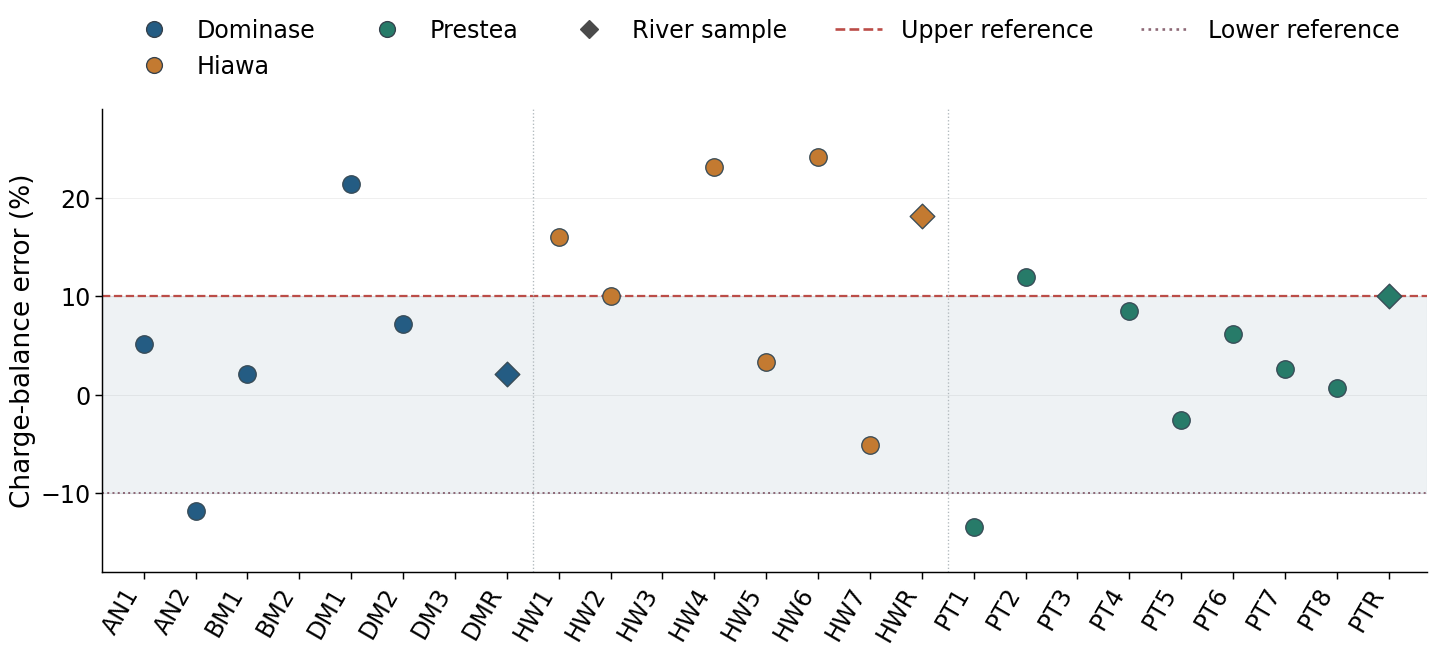

**Figure 5.2 — Measured pH compared with the 6.5–8.5 screening interval**

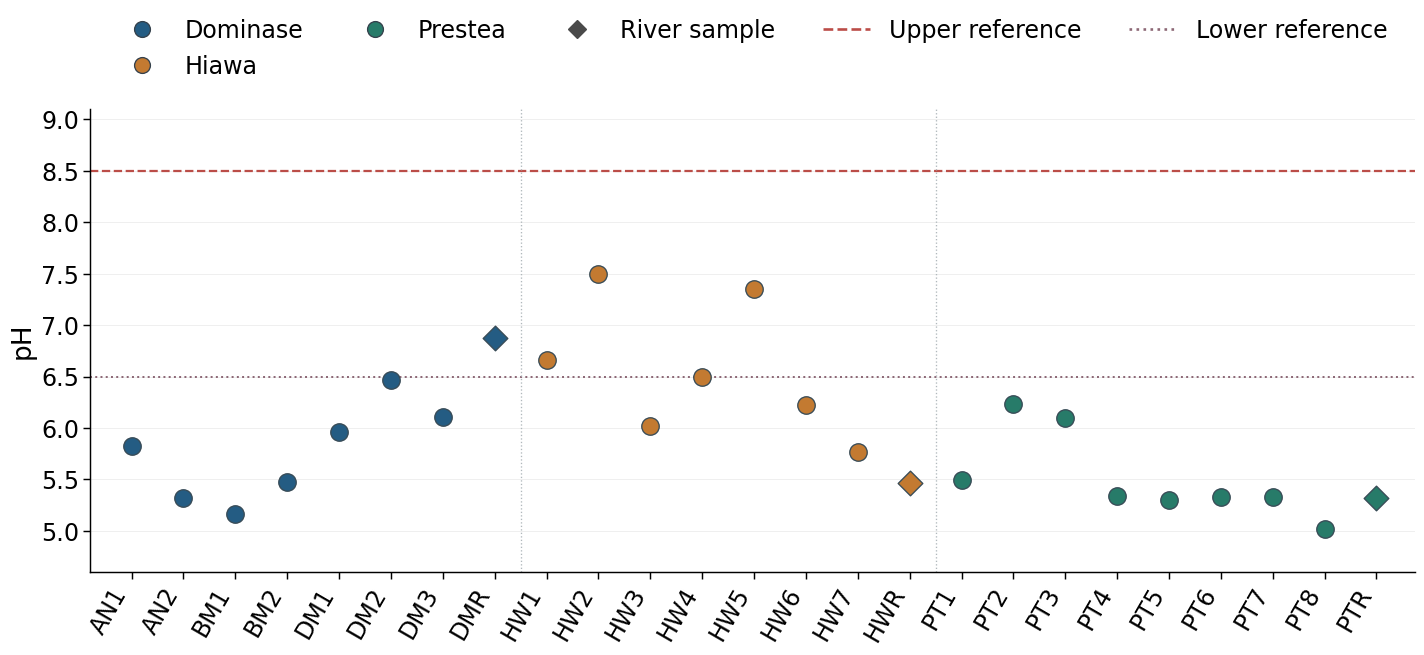

**Figure 5.3 — River turbidity and suspended solids, two distinct concentration scales**

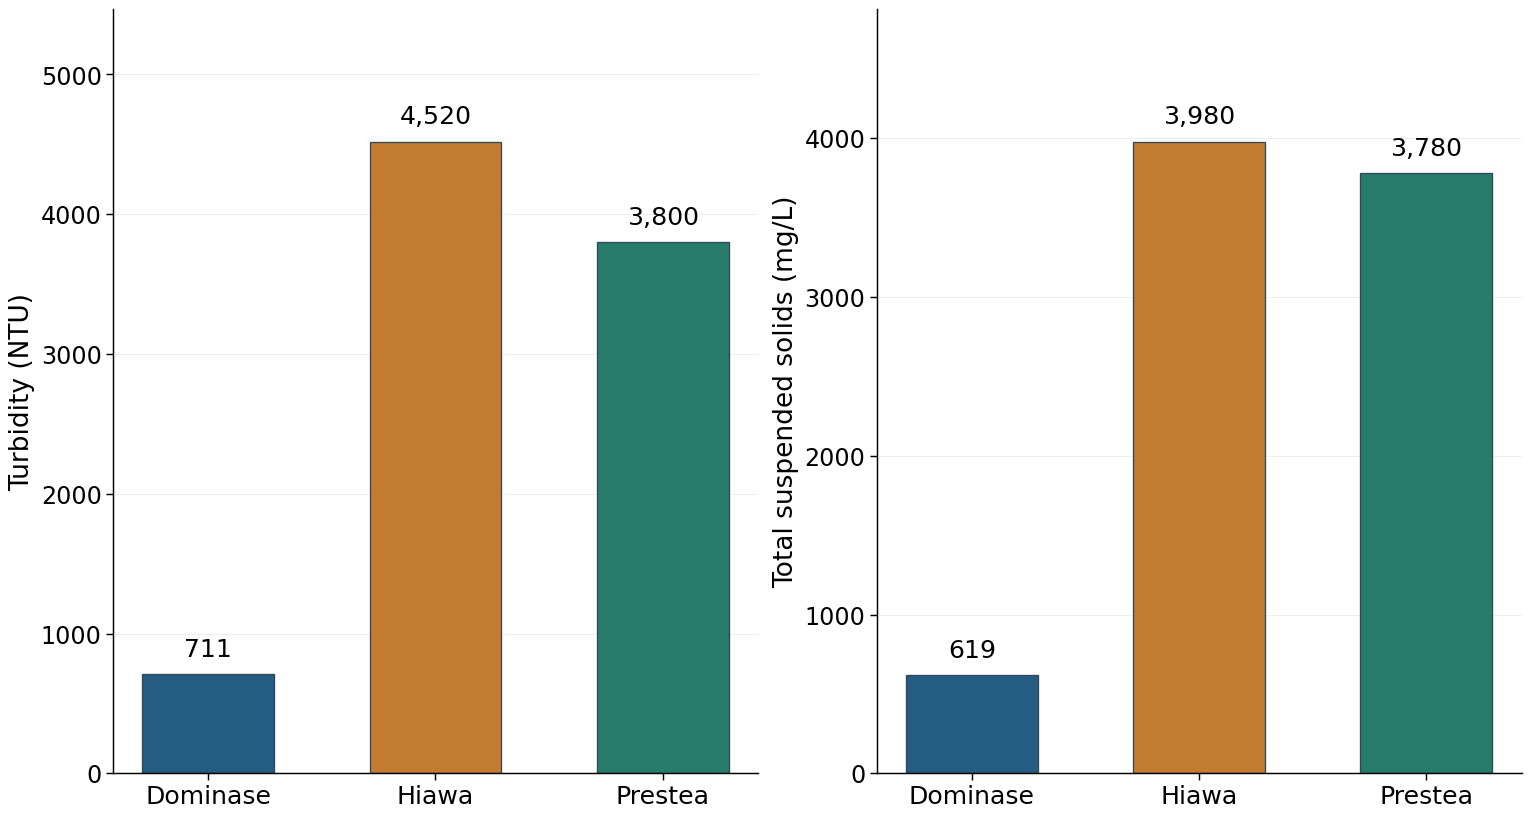

**Figure 5.4 — Groundwater nitrate and censored readings relative to 50 mg/L**

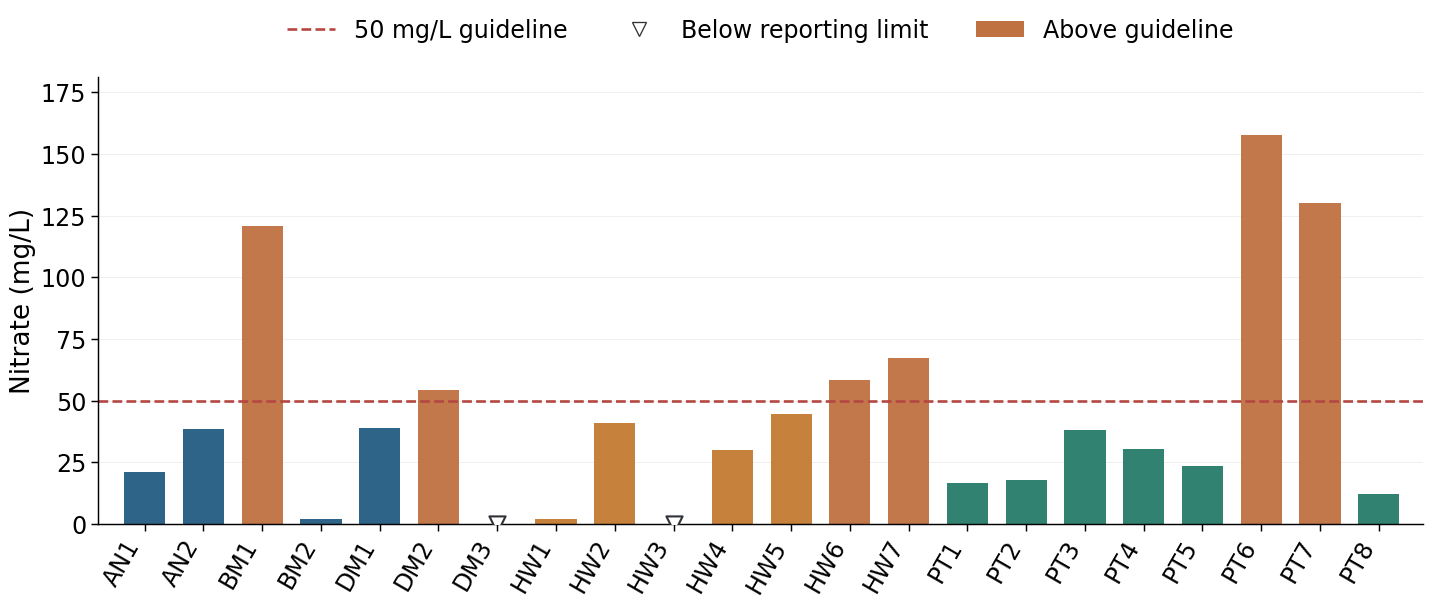

In [6]:
# CELL 6 — graph utilities and common design
from matplotlib.ticker import ScalarFormatter, LogLocator
FIGURE_TITLES={}
SAVE_LOG=[]

def styled_ax(ax,grid=True):
    ax.spines[['right','top']].set_visible(False)
    if grid: ax.grid(axis='y',alpha=.23,ls='-',lw=.65);ax.set_axisbelow(True)
    ax.tick_params(direction='out',length=5,width=1.1)

def finish(fig,number,description,preview=False):
    stem=f'Fig_5_{number:02d}'
    fig.savefig(FIG_DIR/(stem+'.png'),dpi=FIGURE_DPI,bbox_inches='tight',pad_inches=.14)
    fig.savefig(FIG_DIR/(stem+'.pdf'),bbox_inches='tight',pad_inches=.14)
    if preview: fig.savefig(FIG_DIR/(stem+'_preview.png'),dpi=PREVIEW_DPI,bbox_inches='tight')
    FIGURE_TITLES[stem]=description
    SAVE_LOG.append((stem,(FIG_DIR/(stem+'.png')).stat().st_size))
    # Preview directly in Colab. High-resolution export remains unchanged.
    display(Markdown(f'**Figure 5.{number} — {description}**'))
    preview_path=FIG_DIR/(stem+'_preview.png')
    if preview_path.exists():
        display(Image(filename=str(preview_path)))
    else:
        display(Image(filename=str(FIG_DIR/(stem+'.png')),width=1000))
    plt.close(fig)

def grouped_axis(ax,source=m):
    n=len(source);ax.set_xticks(np.arange(n),source.Sample_ID,rotation=60,ha='right',fontsize=18)
    ax.set_xlim(-.8,n-.25)
    boundaries=np.where(source.Community.to_numpy()[1:]!=source.Community.to_numpy()[:-1])[0]
    for b in boundaries:ax.axvline(b+.5,color='#B0B8BC',ls=':',lw=1)

def source_legend(ax):
    h=[Line2D([0],[0],marker='o',color='w',markerfacecolor=PALETTE[c],markeredgecolor='#35414C',markersize=12,label=c) for c in PALETTE]
    h.append(Line2D([0],[0],marker='D',color='#4A4A4A',linestyle='none',markersize=10,label='River sample'))
    return h

def scalar_site_chart(y,ylab,reference=None,lower=None,ylim=None,kind='scatter',legend_more=None):
    fig,ax=plt.subplots(figsize=(18,8.4));styled_ax(ax)
    for i,r in m.reset_index(drop=True).iterrows():
        val=y.iloc[i]
        if not np.isfinite(val):continue
        color=PALETTE[r.Community]; symbol='D' if r.Water_Type=='Surface water' else 'o'
        ax.scatter(i,val,s=175,color=color,marker=symbol,edgecolor='#384B56',linewidth=1.0,zorder=3)
    if reference is not None:ax.axhline(reference,color='#BB4D48',ls='--',lw=1.7,label='Upper guideline / screening value')
    if lower is not None:ax.axhline(lower,color='#8D6876',ls=':',lw=1.5,label='Lower screening value')
    ax.set_ylabel(ylab);grouped_axis(ax)
    if ylim is not None:ax.set_ylim(*ylim)
    handles=source_legend(ax)
    if reference is not None:handles.append(Line2D([0],[0],color='#BB4D48',ls='--',lw=2,label='Upper reference'))
    if lower is not None:handles.append(Line2D([0],[0],color='#8D6876',ls=':',lw=2,label='Lower reference'))
    if legend_more:handles.extend(legend_more)
    ax.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,1.02),ncol=min(len(handles),5),frameon=False,fontsize=18)
    fig.subplots_adjust(top=.82,bottom=.24)
    return fig,ax

# Figure 5.1 ionic charge balance: 21 valid; 4 uncalculated omitted
f,a=scalar_site_chart(m.CBE_recalc,'Charge-balance error (%)',reference=10,lower=-10)
a.axhspan(-10,10,alpha=.12,color='#7995A8');a.set_ylim(-18,29)
finish(f,1,'Ionic charge-balance errors at all calculable sampling locations',True)

# Figure 5.2 pH, 6.5–8.5 screening interval
f,a=scalar_site_chart(m.pH,'pH',reference=8.5,lower=6.5,ylim=(4.6,9.1))
finish(f,2,'Measured pH compared with the 6.5–8.5 screening interval',True)

# Figure 5.3 two comparable panels: avoid mixing NTU and mg/L on one numeric axis
riv=m[m.Water_Type=='Surface water'].copy().reset_index(drop=True)
f,axes=plt.subplots(1,2,figsize=(16,8.5),constrained_layout=True)
for ax,(key,label) in zip(axes,[('Turbidity_NTU_num','Turbidity (NTU)'),('TSS_mg_L_num','Total suspended solids (mg/L)')]):
    styled_ax(ax);vals=riv[key].to_numpy();colors=[PALETTE[c] for c in riv.Community]
    bars=ax.bar(np.arange(3),vals,width=.58,color=colors,edgecolor='#304957')
    ax.set_ylabel(label);ax.set_xticks(np.arange(3),riv.Community,fontsize=19)
    ax.set_ylim(0,max(vals)*1.21)
    for b,v in zip(bars,vals):ax.text(b.get_x()+b.get_width()/2,v+max(vals)*.028,f'{v:,.0f}',ha='center',fontsize=19)
finish(f,3,'River turbidity and suspended solids, two distinct concentration scales',True)

# Figure 5.4 nitrate, censored shown as hollow triangles at baseline, not measured zeros
f,ax=plt.subplots(figsize=(18,8.4));styled_ax(ax)
for i,r in field.reset_index(drop=True).iterrows():
    val=r.NO3_mg_L_num
    if np.isfinite(val):
        ax.bar(i,val,width=.7,color='#C07142' if val>50 else PALETTE[r.Community],alpha=.95)
    else:
        ax.scatter(i,0,s=150,marker='v',facecolors='white',edgecolors='#30343A',lw=1.6,zorder=5)
ax.axhline(50,color='#B44743',ls='--',lw=2)
ax.set_ylabel('Nitrate (mg/L)');ax.set_xticks(np.arange(len(field)),field.Sample_ID,rotation=60,ha='right',fontsize=18)
ax.set_xlim(-.8,len(field)-.25);ax.set_ylim(0,181)
ax.legend(handles=[Line2D([0],[0],color='#B44743',lw=2,ls='--',label='50 mg/L guideline'),Line2D([0],[0],marker='v',mfc='white',mec='#30343A',linestyle='none',markersize=10,label='Below reporting limit'),Rectangle((0,0),1,1,fc='#C07142',label='Above guideline')],loc='lower center',bbox_to_anchor=(.5,1.03),ncol=3,frameon=False)
f.subplots_adjust(top=.82,bottom=.26)
finish(f,4,'Groundwater nitrate and censored readings relative to 50 mg/L',True)

**Figure 5.7 — Arsenic by site with laboratory reporting status and guideline**

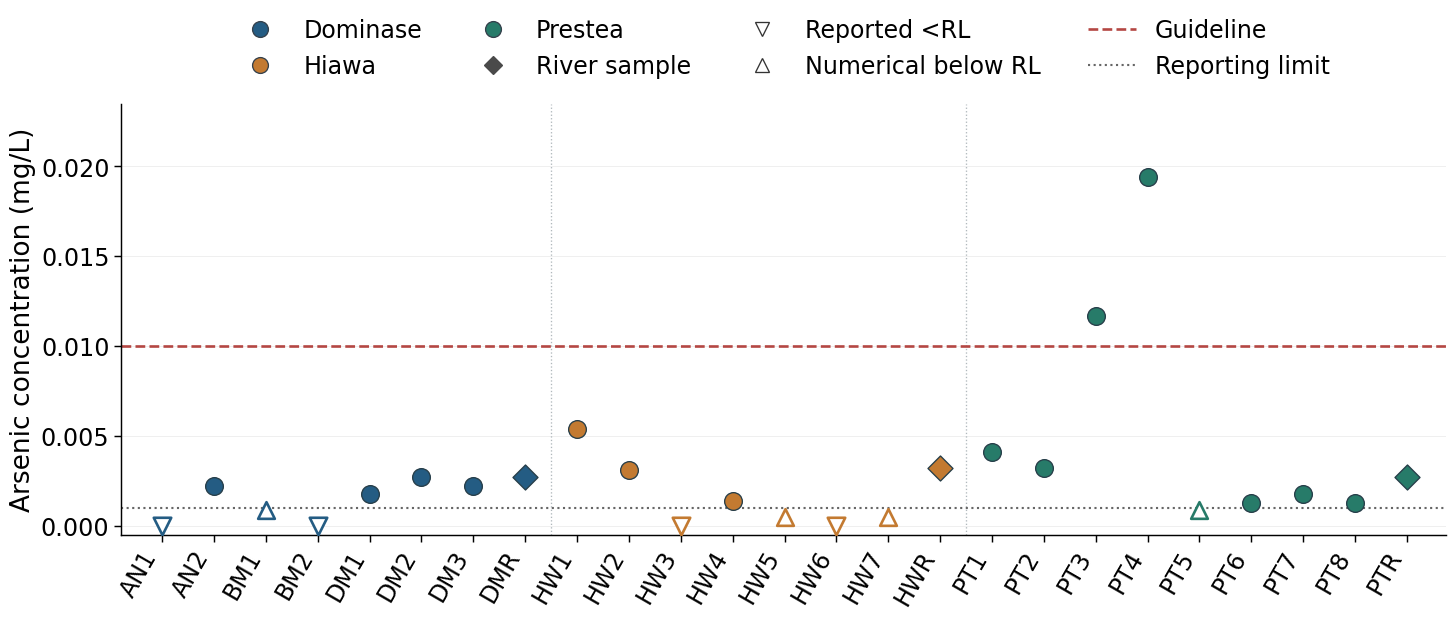

**Figure 5.8 — Mercury by site with laboratory reporting status and guideline**

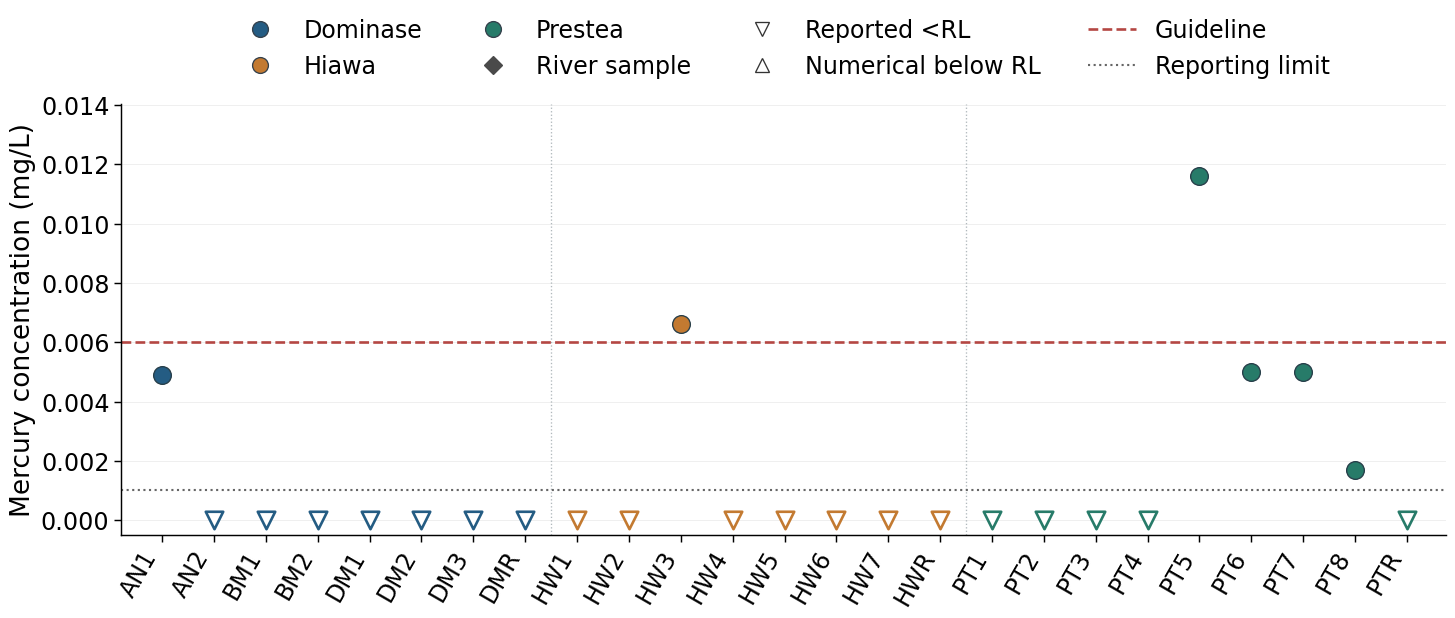

**Figure 5.9 — Distribution of three index classifications and evaluable counts**

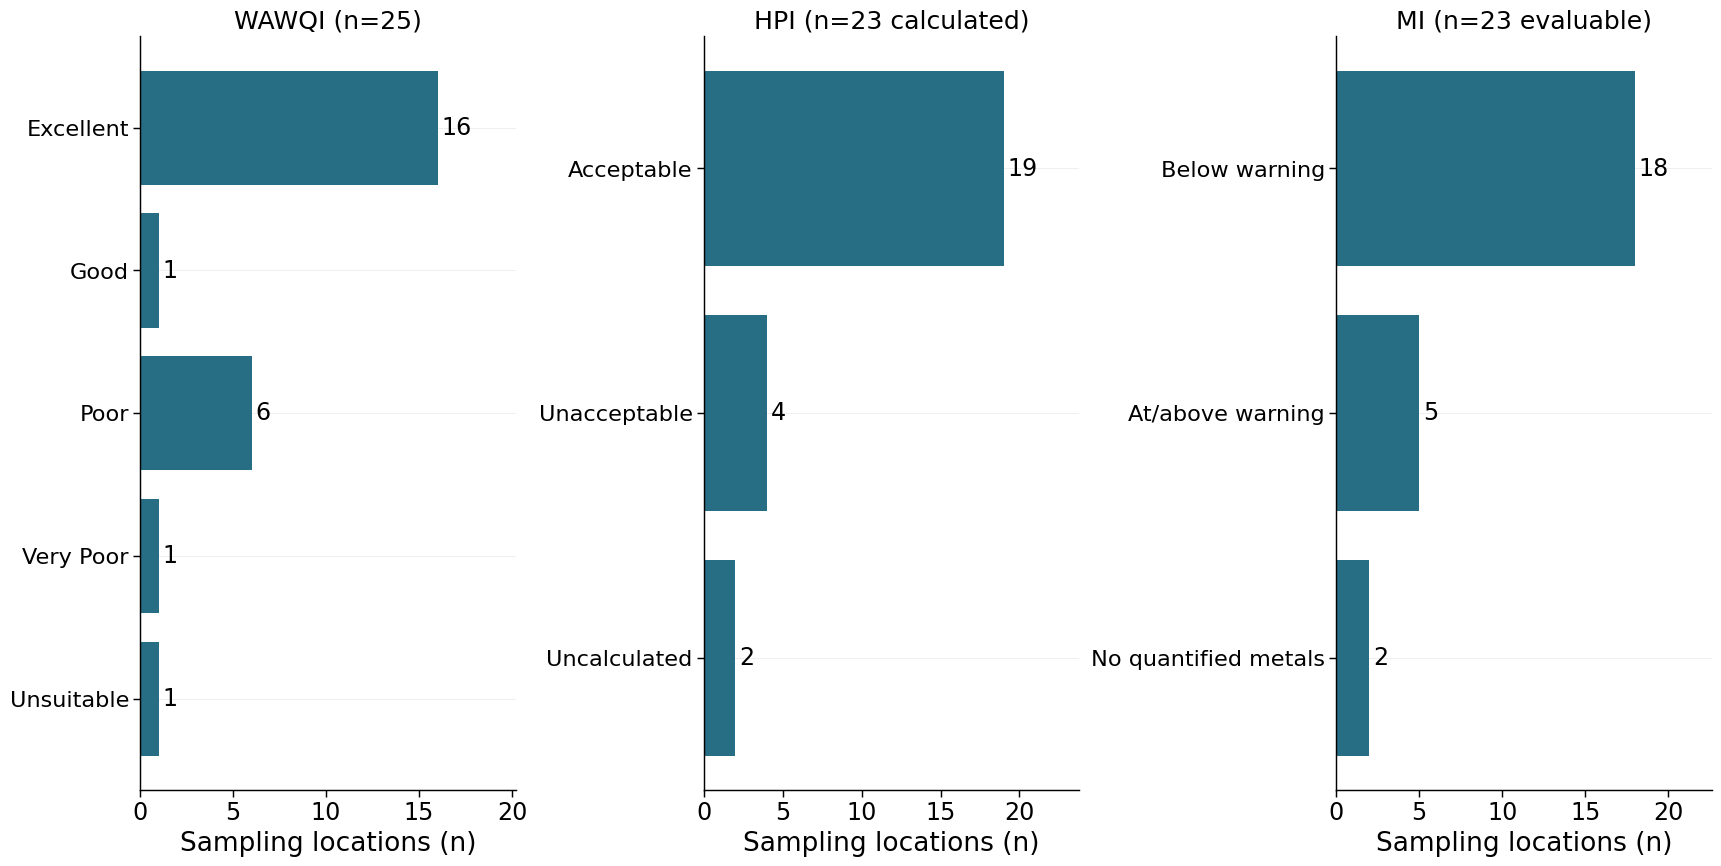

**Figure 5.10 — Oxygen and hydrogen stable isotopes against global and Ghana meteoric lines**

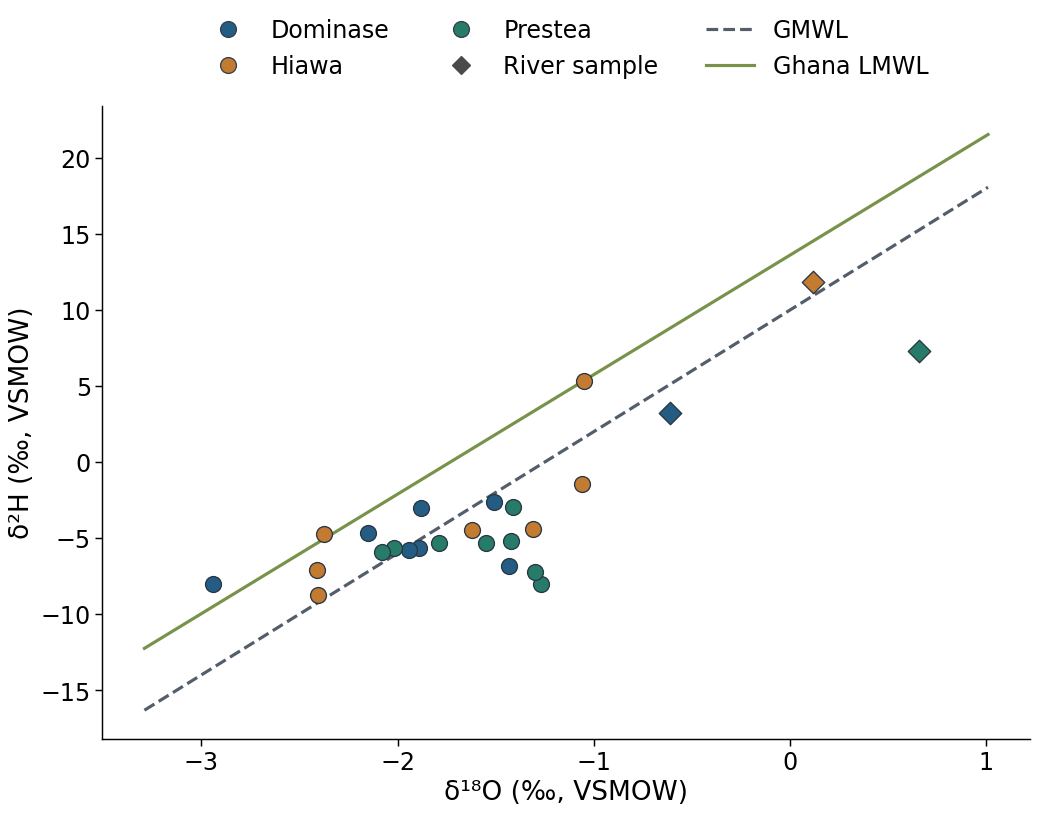

**Figure 5.11 — Site-level deuterium excess relative to 10 per mille reference**

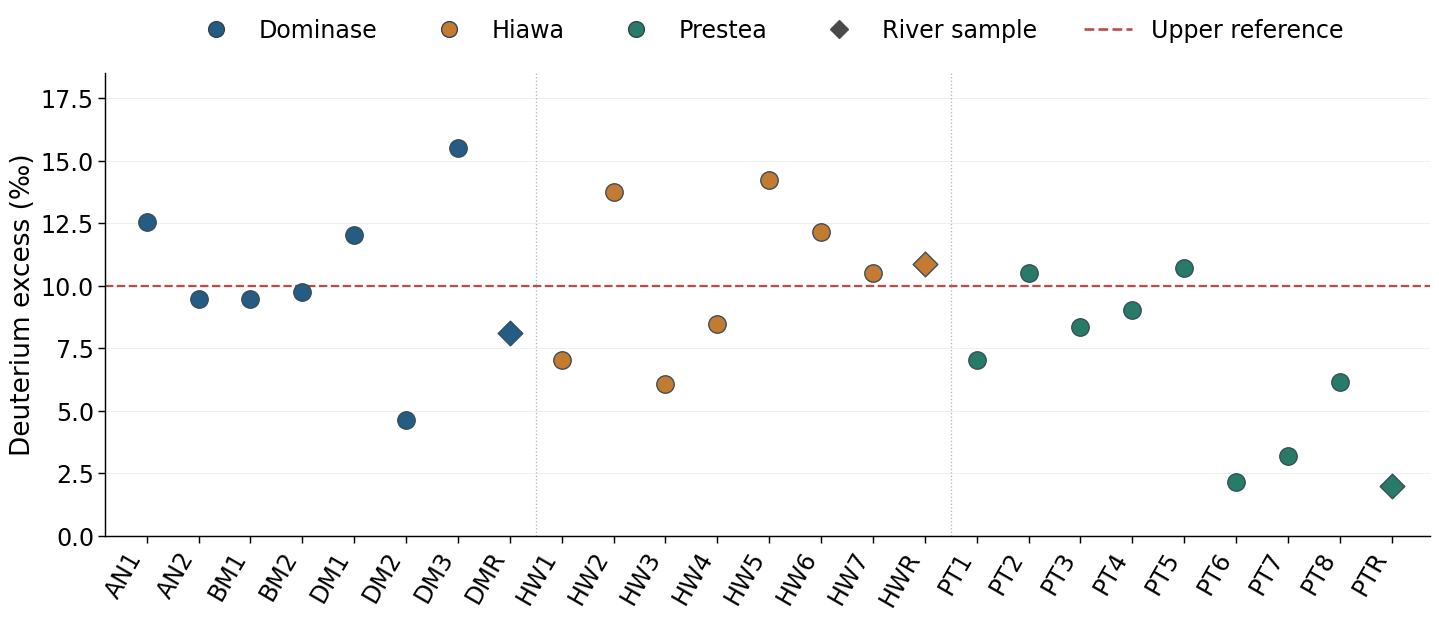

**Figure 5.12 — Site-specific child and adult hazard indices under source exposure assumptions**

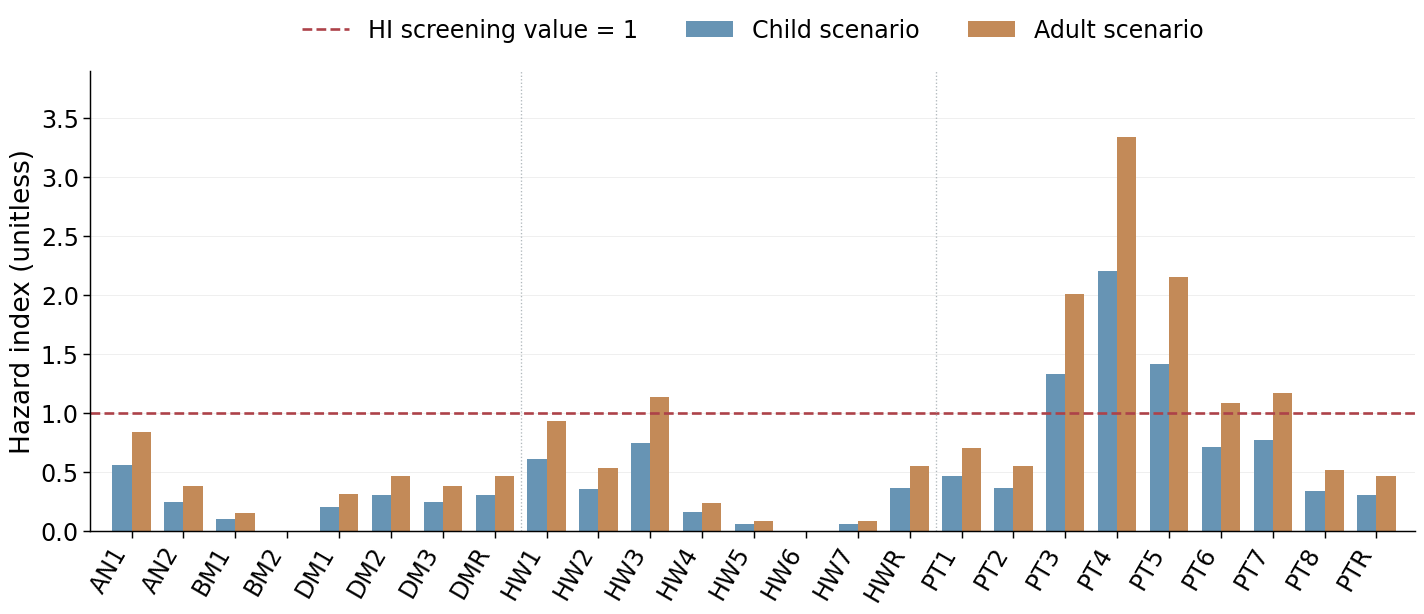

**Figure 5.13 — Arsenic carcinogenic risk under the workbook original toxicity values**

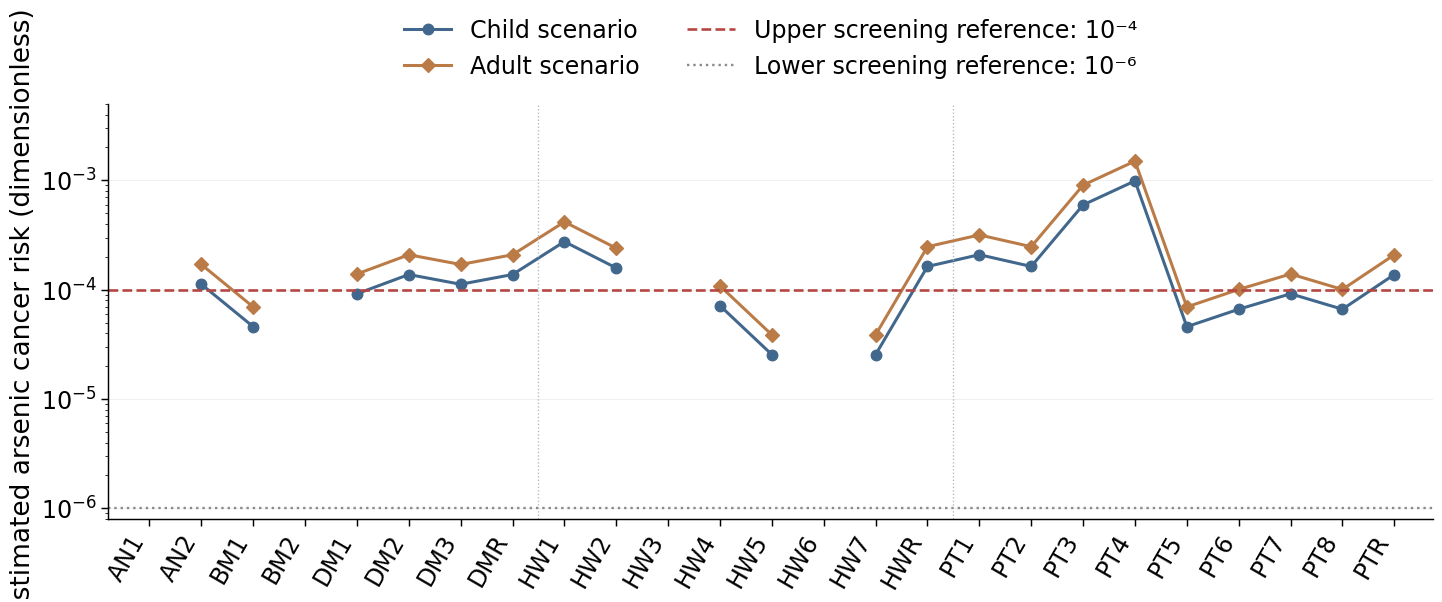

PASS — manuscript figures generated: ['Fig_5_01', 'Fig_5_02', 'Fig_5_03', 'Fig_5_04', 'Fig_5_07', 'Fig_5_08', 'Fig_5_09', 'Fig_5_10', 'Fig_5_11', 'Fig_5_12', 'Fig_5_13']
Ghana meteoric-line coefficients from original workbook: 7.859999999999997 13.609999999999985


In [7]:
# CELL 7 — heavy metals, indices, stable isotopes and health risk
# 5.7 and 5.8: split numeric below-RL values from original <RL strings
def metal_plot(col,name,guide,rl,n):
    fig,ax=plt.subplots(figsize=(18,8.4));styled_ax(ax)
    values=m[col+'_num']
    for i,r in m.reset_index(drop=True).iterrows():
        y=values.iloc[i];edge=PALETTE[r.Community]
        mark='D' if r.Water_Type=='Surface water' else 'o'
        if pd.isna(y):
            ax.scatter(i,0,s=175,marker='v',facecolors='white',edgecolors=edge,lw=2,zorder=4)
        elif y<rl:
            ax.scatter(i,y,s=160,marker='^',facecolors='white',edgecolors=edge,lw=2,zorder=5)
        else:
            ax.scatter(i,y,s=180,marker=mark,color=edge,edgecolor='#263D48',zorder=4)
    grouped_axis(ax);ax.axhline(guide,ls='--',color='#B44743',lw=2)
    ax.axhline(rl,ls=':',color='#666666',lw=1.6)
    ax.set_ylabel(name+' concentration (mg/L)');ax.set_ylim(-.0005,max(guide*1.25,values.max()*1.21))
    handles=source_legend(ax)+[Line2D([0],[0],marker='v',mfc='white',mec='#333',color='white',markersize=11,label='Reported <RL'),Line2D([0],[0],marker='^',mfc='white',mec='#333',color='white',markersize=11,label='Numerical below RL'),Line2D([0],[0],color='#B44743',ls='--',lw=2,label='Guideline'),Line2D([0],[0],color='#666',ls=':',lw=1.6,label='Reporting limit')]
    ax.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,1.01),ncol=4,frameon=False)
    fig.subplots_adjust(top=.79,bottom=.25)
    finish(fig,n,f'{name} by site with laboratory reporting status and guideline',True)
metal_plot('As_mg_L','Arsenic',.010,.001,7)
metal_plot('Hg_mg_L','Mercury',.006,.001,8)

# Figure 5.9 comparative distribution, with different denominators clearly labelled
fig,axes=plt.subplots(1,3,figsize=(18,9),constrained_layout=True)
sections=[('WAWQI (n=25)',m.WQI_Class.value_counts(),['Excellent','Good','Poor','Very Poor','Unsuitable']),('HPI (n=23 calculated)',pd.Series({'Acceptable':(m.HPI<100).sum(),'Unacceptable':(m.HPI>=100).sum(),'Uncalculated':m.HPI.isna().sum()}),['Acceptable','Unacceptable','Uncalculated']),('MI (n=23 evaluable)',pd.Series({'Below warning':mi_re.lt(1).sum(),'At/above warning':mi_re.ge(1).sum(),'No quantified metals':mi_re.isna().sum()}),['Below warning','At/above warning','No quantified metals'])]
for ax,(heading,count,cats) in zip(axes,sections):
    styled_ax(ax);y=np.arange(len(cats));v=[int(count.get(c,0)) for c in cats];bars=ax.barh(y,v,color='#276D84')
    ax.set_yticks(y,cats,fontsize=17);ax.invert_yaxis();ax.set_xlabel('Sampling locations (n)');ax.set_title(heading,fontsize=19)
    ax.set_xlim(0,max(v)*1.20+1)
    for b,t in zip(bars,v):ax.text(b.get_width()+.22,b.get_y()+b.get_height()/2,str(t),va='center',fontsize=18)
finish(fig,9,'Distribution of three index classifications and evaluable counts',True)

# Figure 5.10 isotope relationships; meteorics derived from original isotope workbook helper values
iso=SHEETS['Isotopes'].copy()
a_ghana,b_ghana=np.polyfit(iso.d18O_permille.to_numpy(),iso.Ghana_LMWL_d2H.to_numpy(),1)
assert np.allclose(a_ghana*iso.d18O_permille+b_ghana,iso.Ghana_LMWL_d2H,atol=1e-10)
fig,ax=plt.subplots(figsize=(13.2,10.1));styled_ax(ax,False)
xx=np.linspace(m.d18O_permille.min()-.35,m.d18O_permille.max()+.35,100)
ax.plot(xx,8*xx+10,ls='--',lw=2.4,color='#545E6B',label='Global meteoric water line')
ax.plot(xx,a_ghana*xx+b_ghana,ls='-',lw=2.4,color='#79924A',label='Ghana meteoric water line')
for place in ['Dominase','Hiawa','Prestea']:
    for wt,marker in [('Groundwater','o'),('Surface water','D')]:
        g=m[(m.Community==place)&(m.Water_Type==wt)]
        ax.scatter(g.d18O_permille,g.d2H_permille,s=145,marker=marker,color=PALETTE[place],edgecolors='#283743',zorder=4)
ax.set_xlabel('δ¹⁸O (‰, VSMOW)');ax.set_ylabel('δ²H (‰, VSMOW)')
handles=source_legend(ax)+[Line2D([0],[0],color='#545E6B',ls='--',lw=2.4,label='GMWL'),Line2D([0],[0],color='#79924A',lw=2.4,label='Ghana LMWL')]
ax.legend(handles=handles,loc='lower center',bbox_to_anchor=(.5,1.01),ncol=3,frameon=False,fontsize=18)
fig.subplots_adjust(top=.81,bottom=.15,left=.16)
finish(fig,10,'Oxygen and hydrogen stable isotopes against global and Ghana meteoric lines',True)

# Figure 5.11 d-excess
f,a=scalar_site_chart(m.d_excess_permille,'Deuterium excess (‰)',reference=10,ylim=(0,18.5))
finish(f,11,'Site-level deuterium excess relative to 10 per mille reference',True)

# Figure 5.12 child–adult HI, missing both metals are left blank, not zero
fig,ax=plt.subplots(figsize=(18,8.5));styled_ax(ax)
index=np.arange(len(m));child=m.HI_Child.to_numpy();adult=m.HI_Adult.to_numpy();wd=.37
ax.bar(index-wd/2,child,wd,label='Child scenario',color='#6794B4')
ax.bar(index+wd/2,adult,wd,label='Adult scenario',color='#C38A58')
ax.axhline(1,ls='--',color='#AD4249',lw=2,label='HI screening value = 1')
ax.set_ylabel('Hazard index (unitless)');grouped_axis(ax);ax.set_ylim(0,3.9)
ax.legend(loc='lower center',bbox_to_anchor=(.5,1.015),ncol=3,frameon=False)
fig.subplots_adjust(top=.82,bottom=.25)
finish(fig,12,'Site-specific child and adult hazard indices under source exposure assumptions',True)

# Figure 5.13 log-scale LCR; NaN stays missing, no zeros for censored arsenic
fig,ax=plt.subplots(figsize=(18,8.4));styled_ax(ax)
ch=m.LCR_As_Child.to_numpy();ad=m.LCR_As_Adult.to_numpy()
ax.plot(index,ch,color='#41678C',marker='o',markersize=8,lw=2.3,label='Child scenario')
ax.plot(index,ad,color='#BA7B47',marker='D',markersize=8,lw=2.3,label='Adult scenario')
ax.axhline(1e-4,color='#B44743',ls='--',lw=2,label='Upper screening reference: 10⁻⁴')
ax.axhline(1e-6,color='#8B8B8B',ls=':',lw=1.8,label='Lower screening reference: 10⁻⁶')
ax.set_yscale('log');ax.set_ylim(8e-7,5e-3);ax.set_ylabel('Estimated arsenic cancer risk (dimensionless)');grouped_axis(ax)
ax.legend(loc='lower center',bbox_to_anchor=(.5,1.01),ncol=2,frameon=False)
fig.subplots_adjust(top=.78,bottom=.26)
finish(fig,13,'Arsenic carcinogenic risk under the workbook original toxicity values',True)
print('PASS — manuscript figures generated:',[r[0] for r in SAVE_LOG])
print('Ghana meteoric-line coefficients from original workbook:',a_ghana,b_ghana)

## 6. Supplementary measured-location maps and final audit

These are **point maps, not IDW surfaces**. Geographic plotting is based exclusively on the supplied Easting and Northing values; no invented intermediate concentrations appear. Coordinate reference metadata should be confirmed against original GPS notes before overlaying other GIS data. Cadmium and lead remain censored at all sites.

**pH — measured geographical locations**

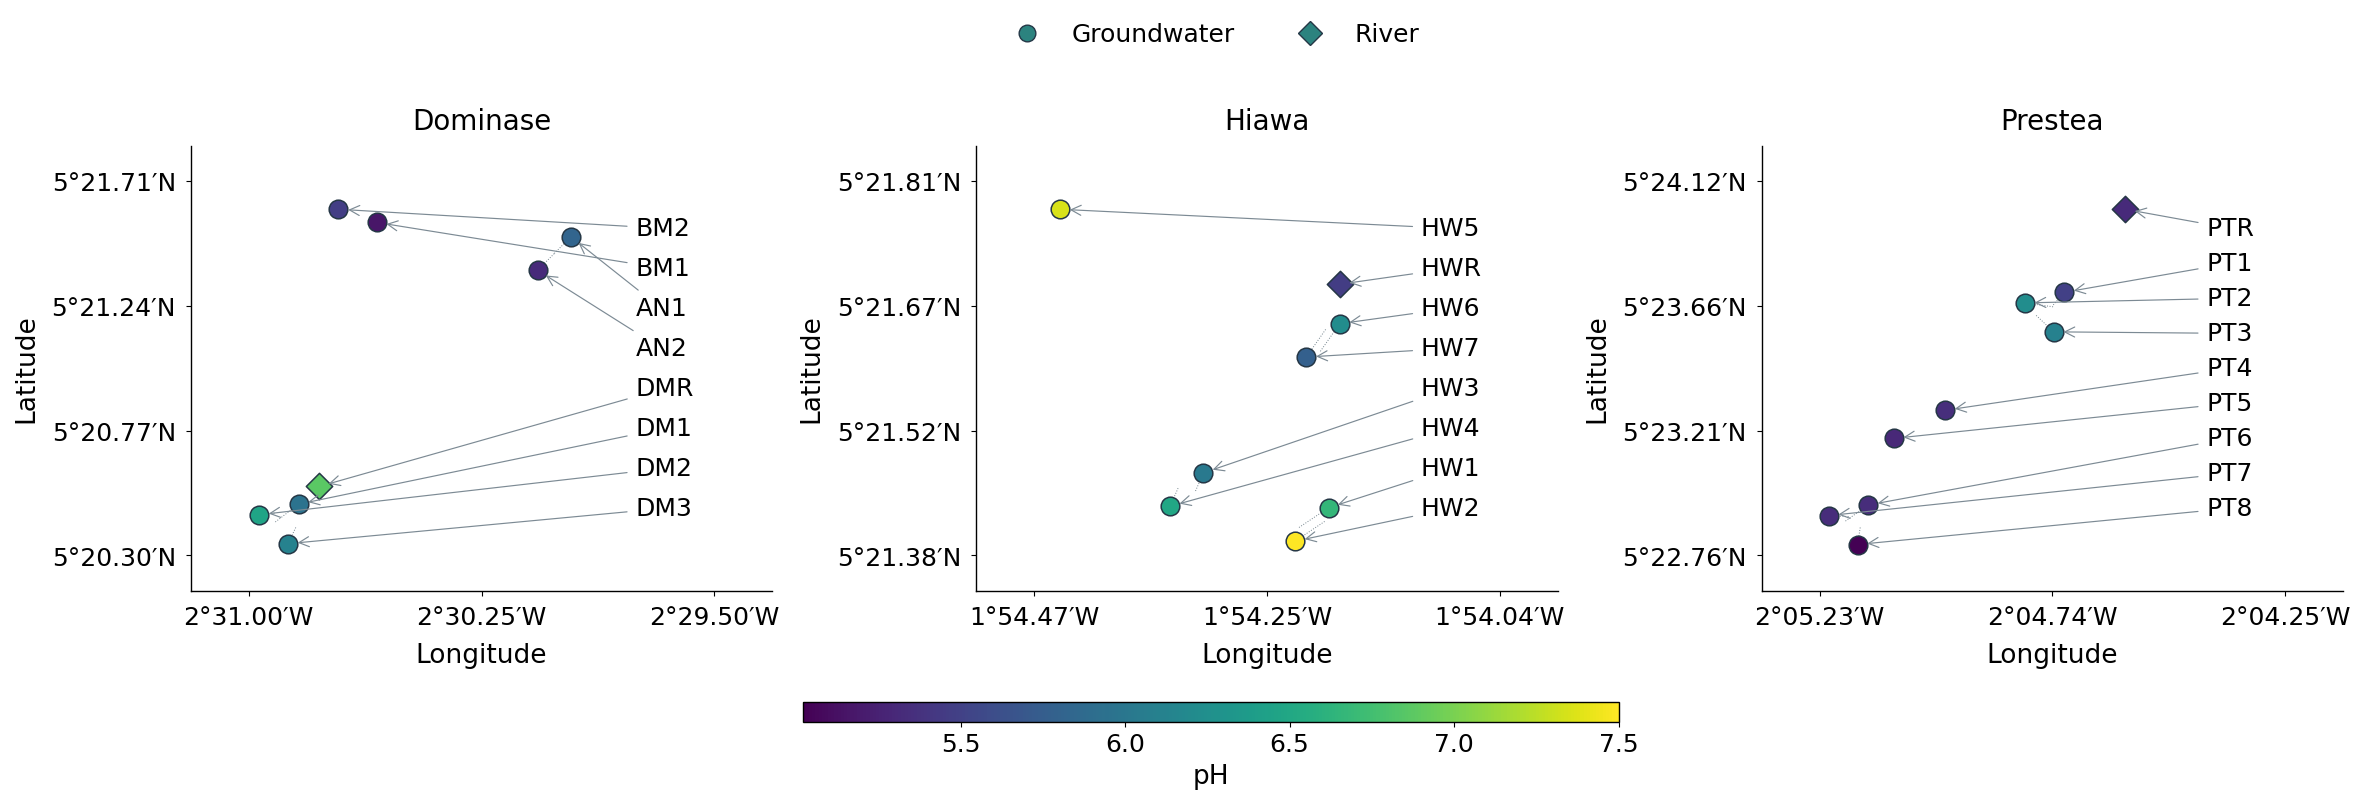

PASS — pH: 25 locations; 25 quantified values.


**EC — measured geographical locations**

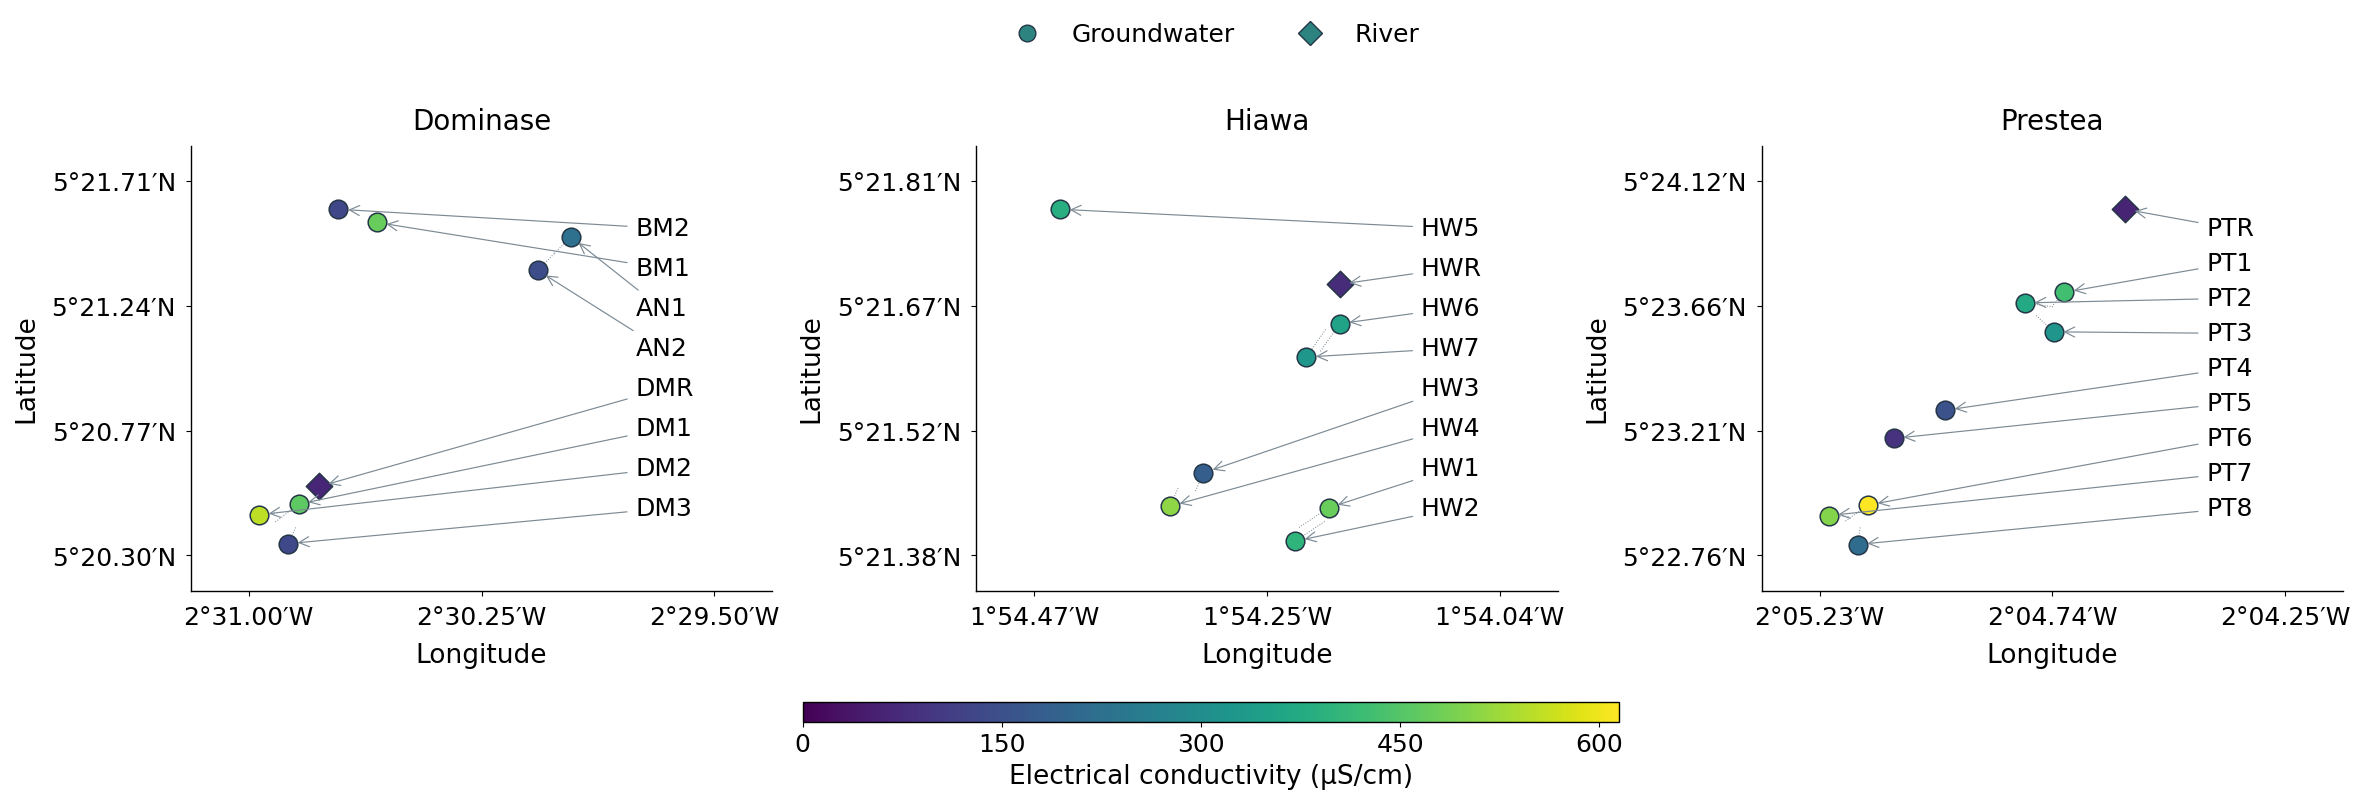

PASS — EC: 25 locations; 25 quantified values.


**TDS — measured geographical locations**

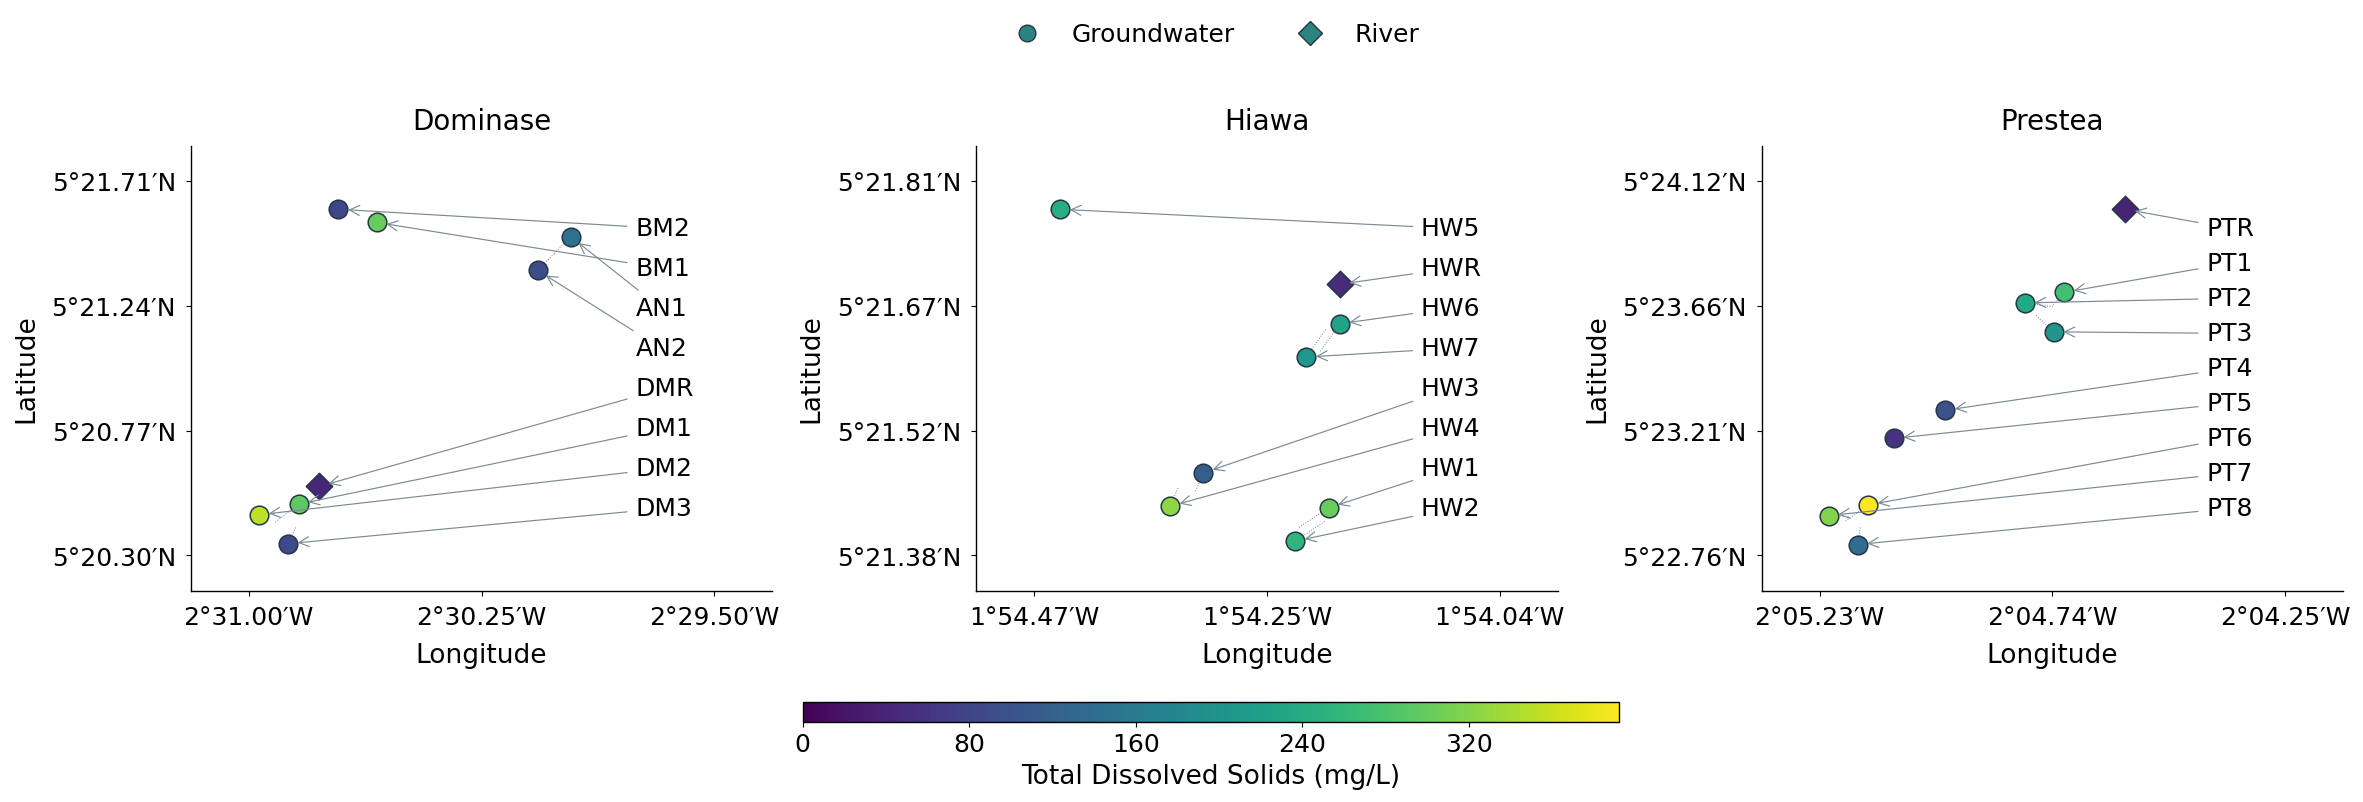

PASS — TDS: 25 locations; 25 quantified values.


**Na — measured geographical locations**

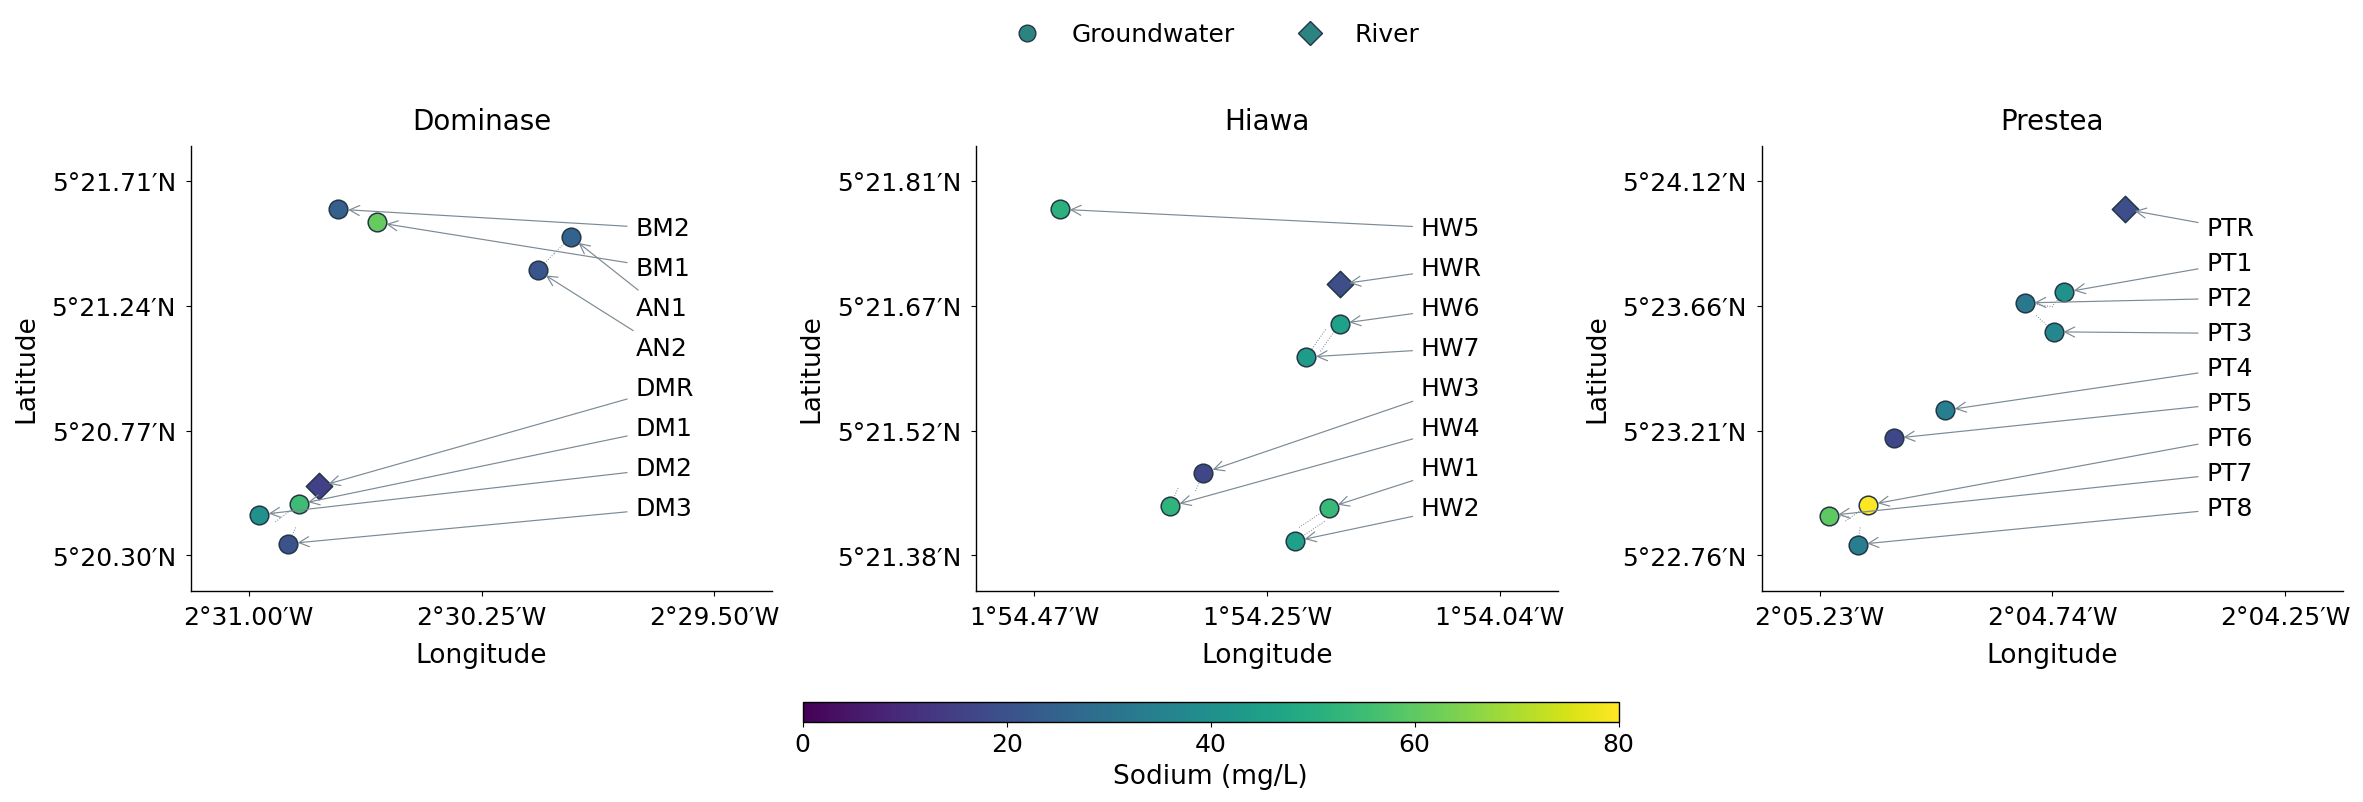

PASS — Na: 25 locations; 25 quantified values.


**K — measured geographical locations**

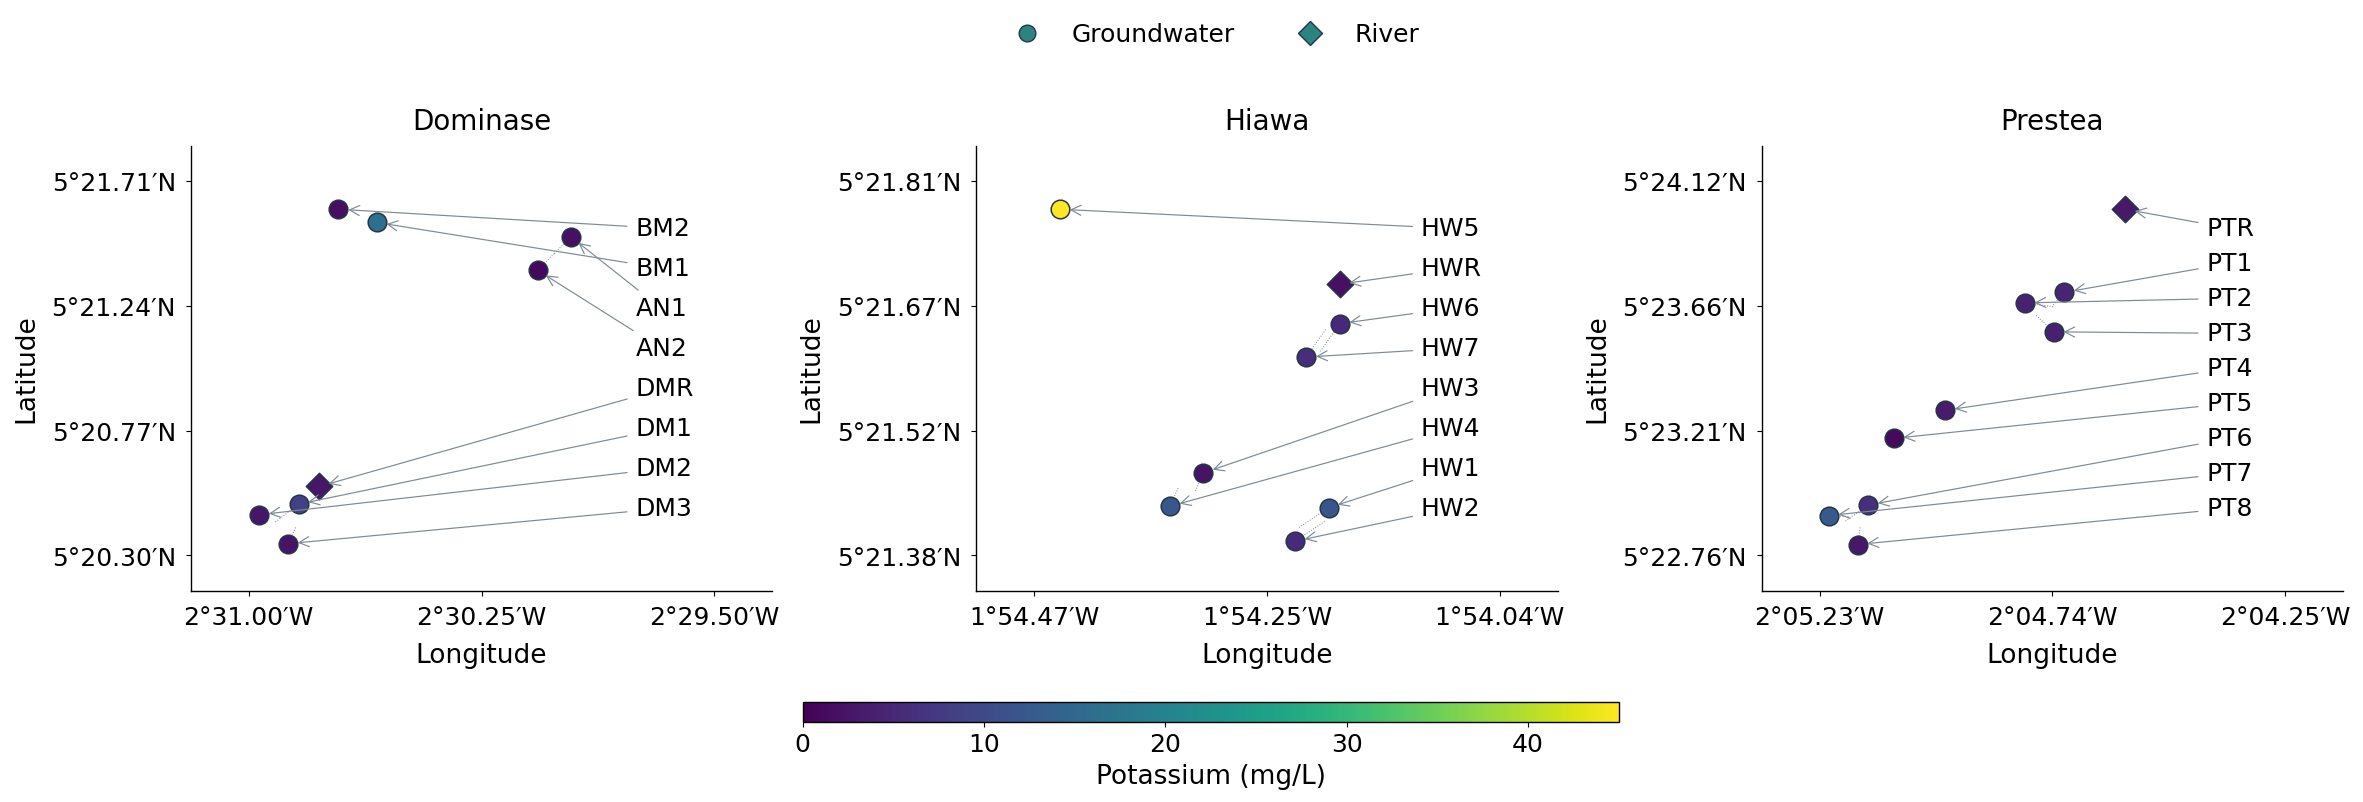

PASS — K: 25 locations; 25 quantified values.


**Ca — measured geographical locations**

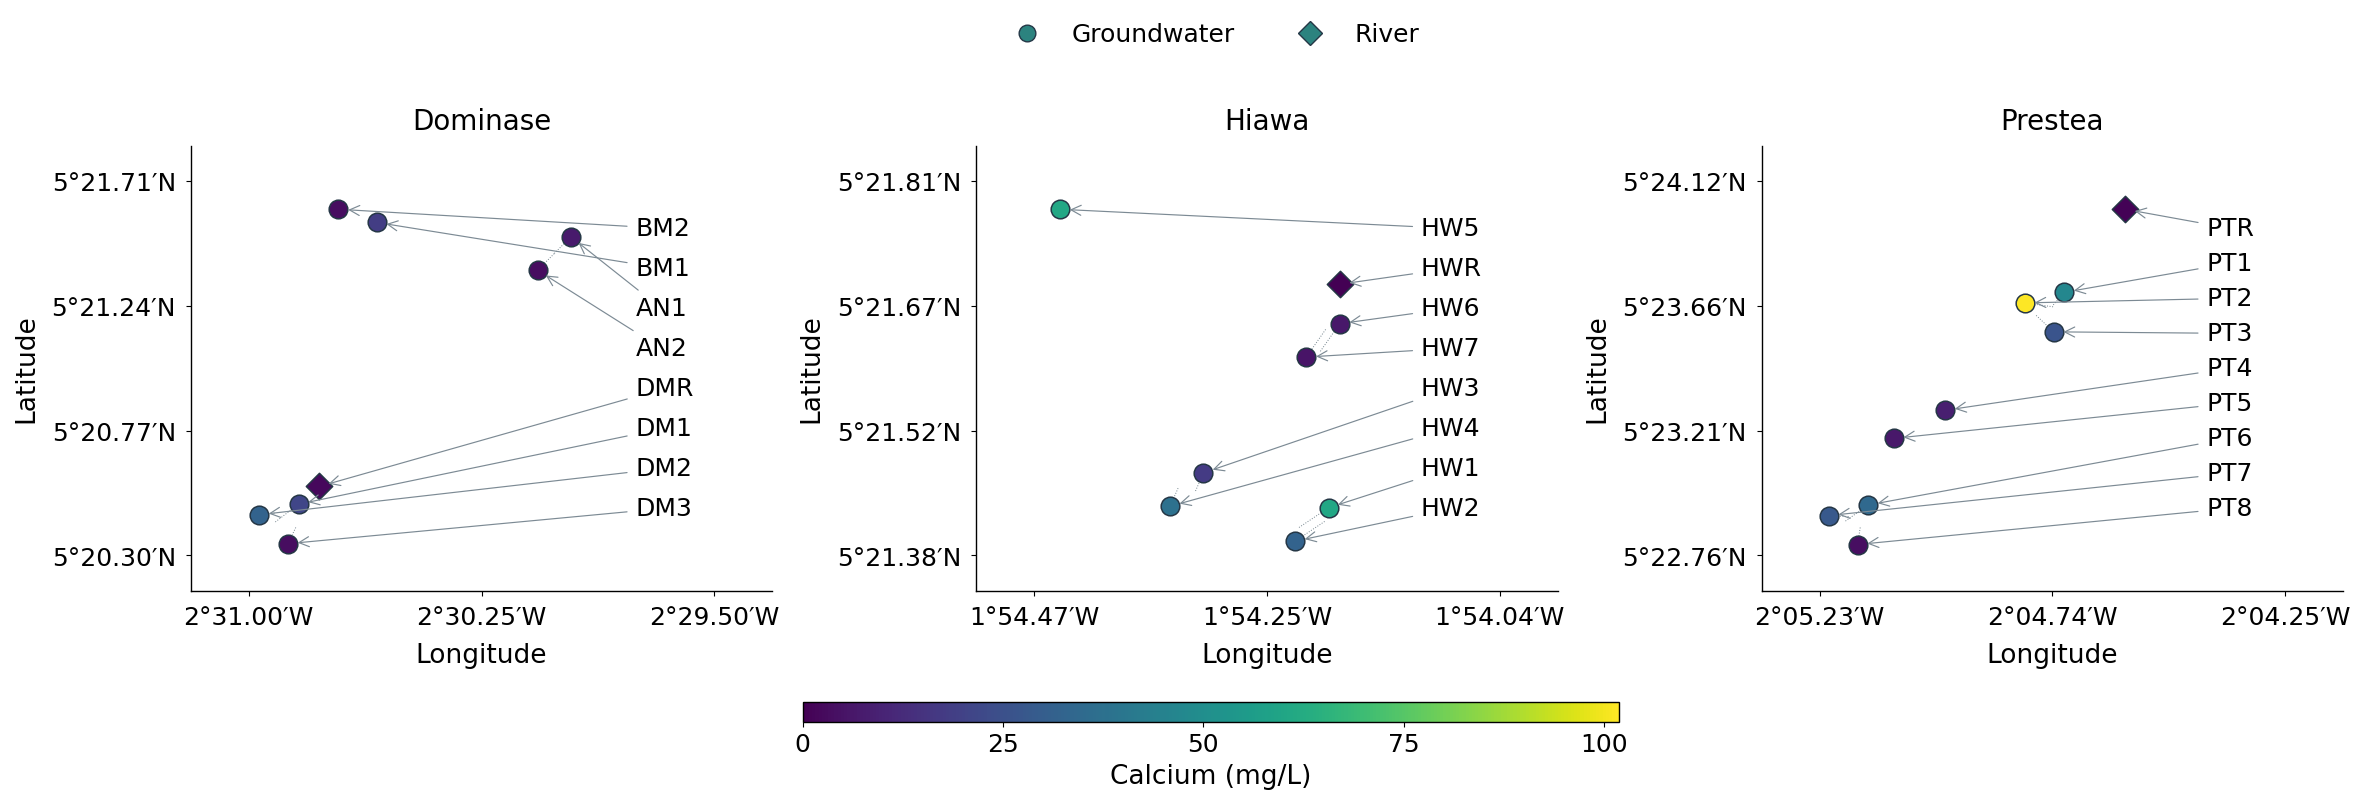

PASS — Ca: 25 locations; 25 quantified values.


**As — measured geographical locations**

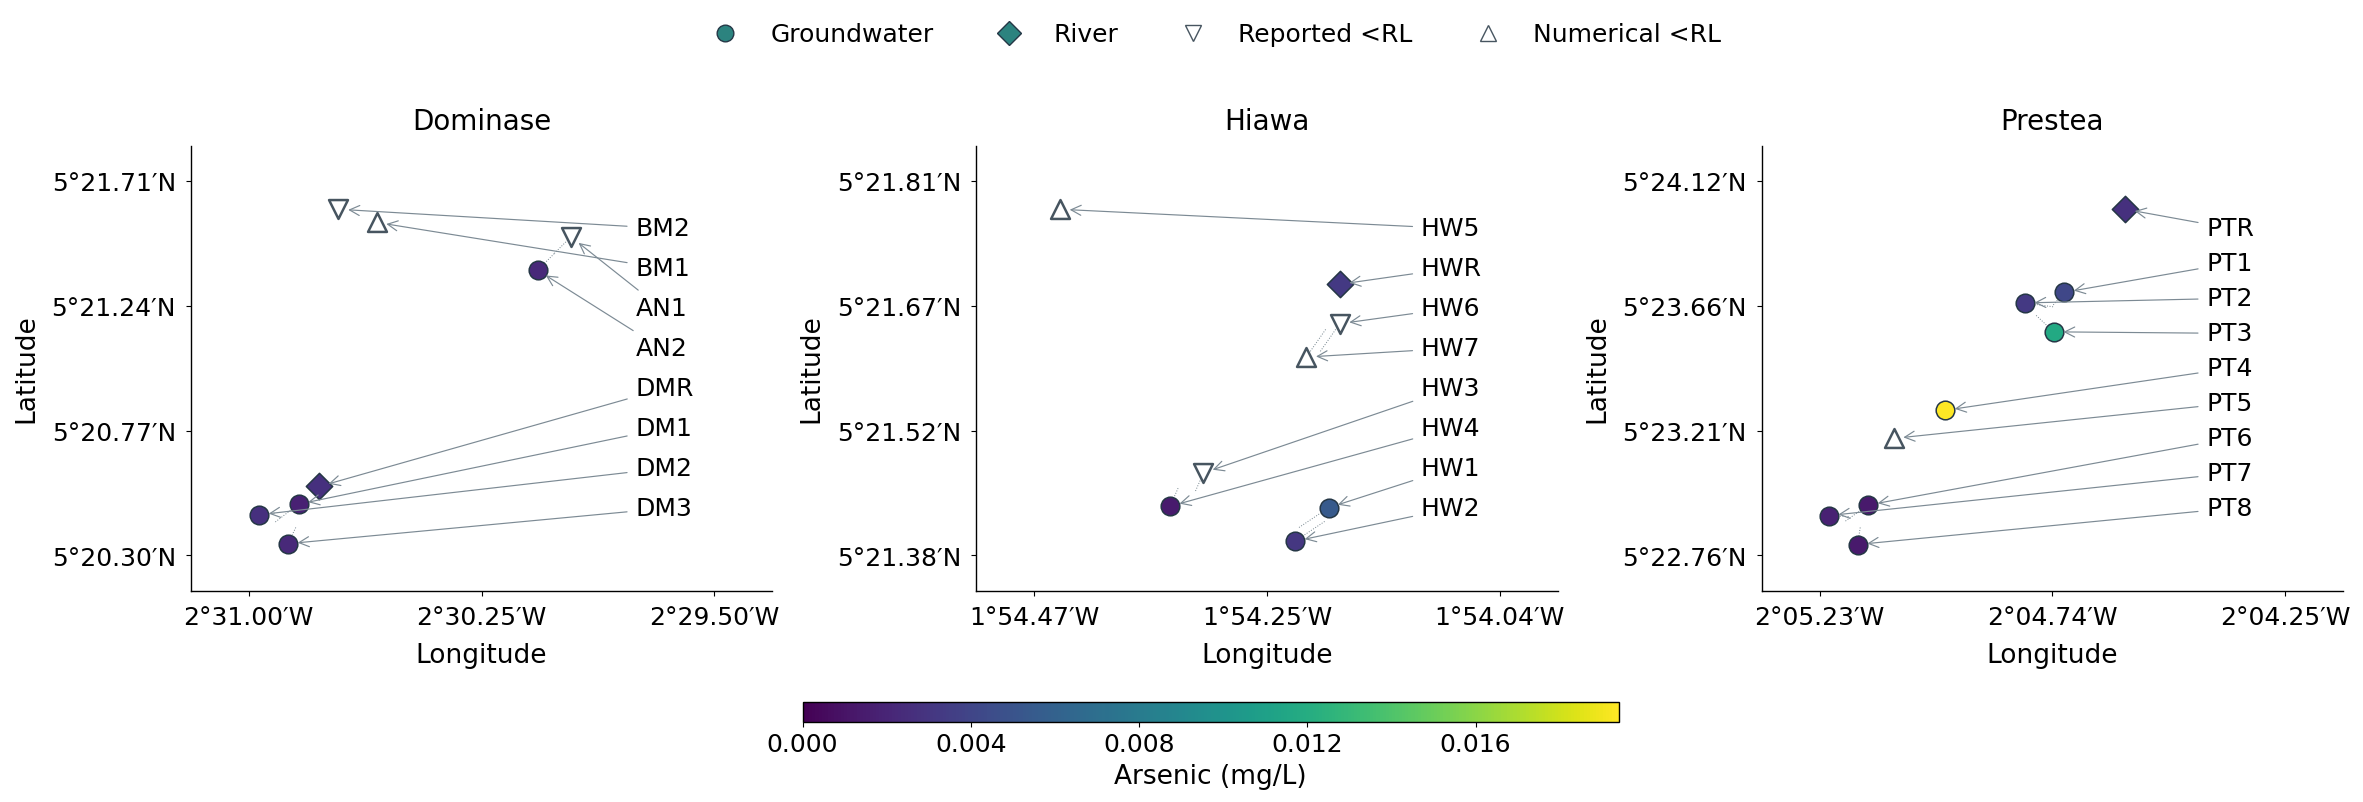

PASS — As: 25 locations; 17 quantified values.


**Hg — measured geographical locations**

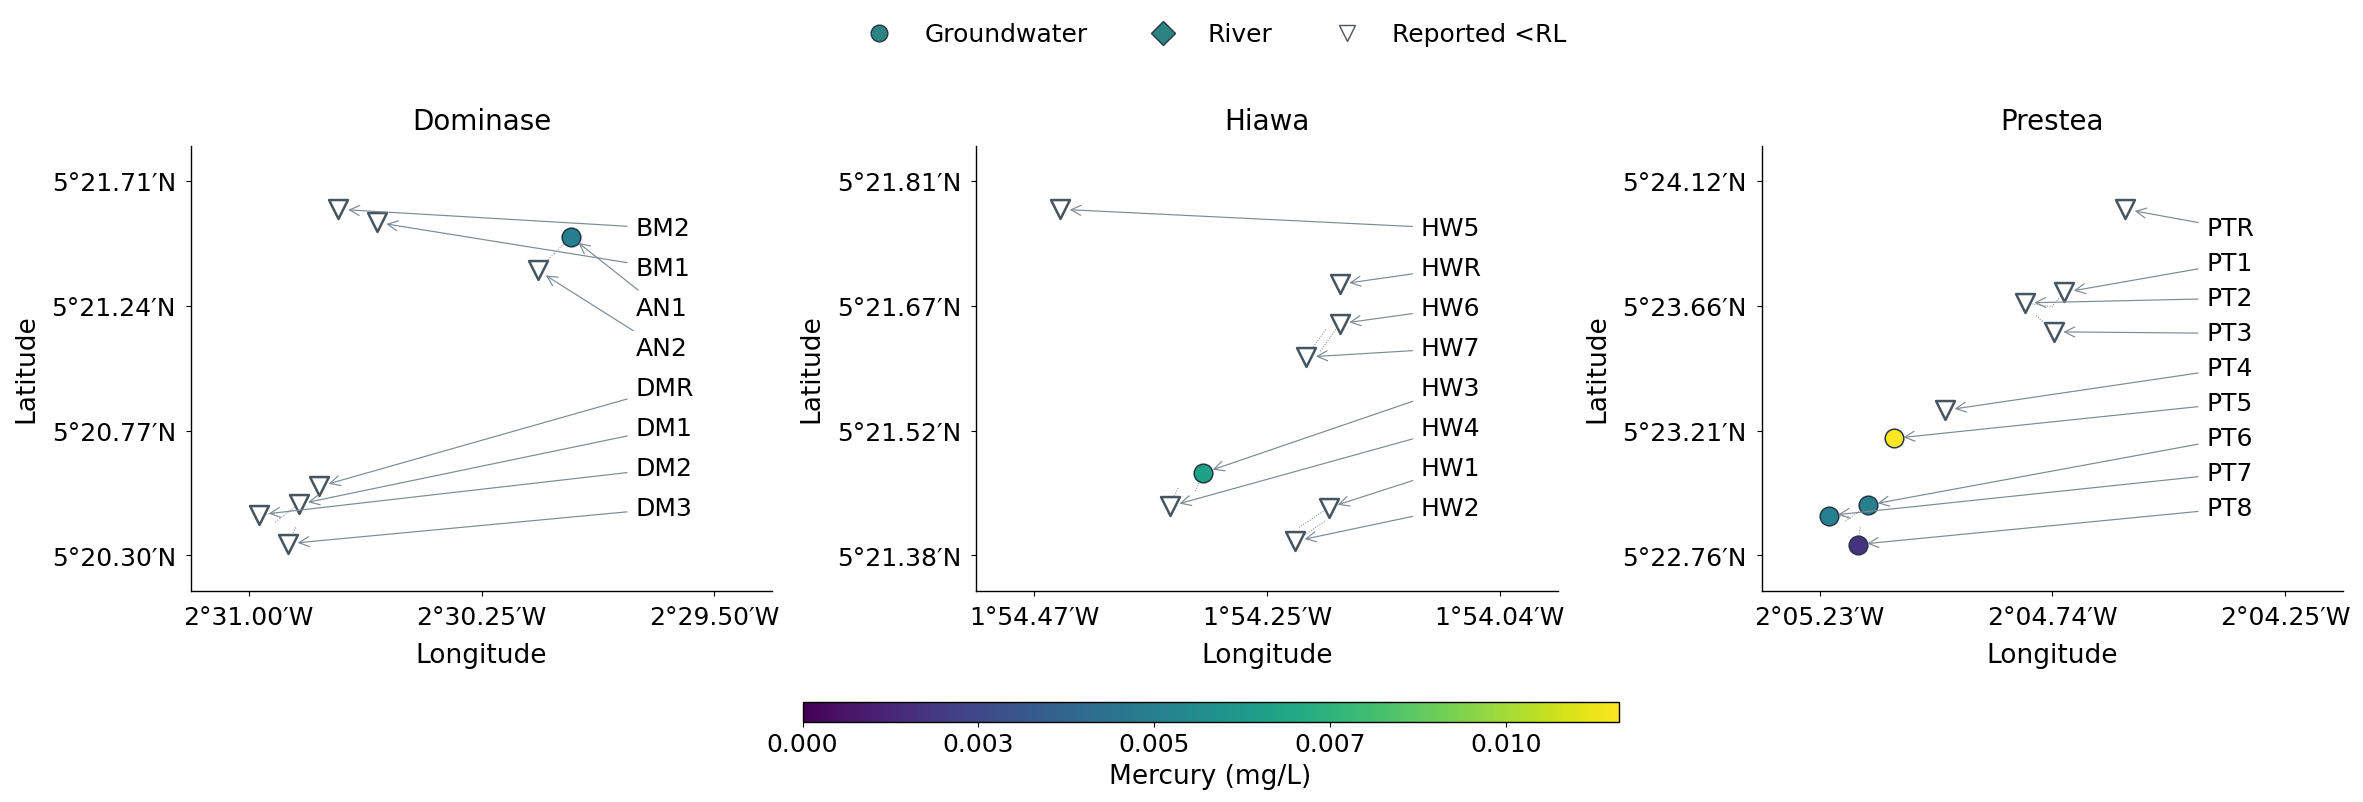

PASS — Hg: 25 locations; 6 quantified values.
PASS — Eight figures generated. Three longitude and four latitude coordinates per panel. Original UTM coordinates preserved.


In [15]:

# CELL 8 — EIGHT GEOGRAPHIC POINT MAPS
# Tested against Chapter_5_Master_Analysis.xlsx / Master_Data
# WGS84 longitude and latitude, in degrees and decimal minutes
# 3 longitude ticks, 4 latitude ticks per panel
# Straight label arrows; original coordinates preserved

import gc
import sys
import subprocess
import importlib.util
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
from matplotlib.ticker import (
    FixedLocator, FuncFormatter,
    MaxNLocator, FormatStrFormatter
)
from IPython.display import display, Markdown, Image

if importlib.util.find_spec("pyproj") is None:
    subprocess.check_call([
        sys.executable, "-m", "pip", "install", "pyproj"
    ])

from pyproj import Transformer

# ---------------------------------------------------------
# 1. LOAD ORIGINAL MASTER WORKBOOK
# ---------------------------------------------------------

WORKBOOK = Path(
    globals().get(
        "INPUT_FILE",
        "/content/drive/MyDrive/PRISCY_PHIL/"
        "Chapter_5_Master_Analysis.xlsx"
    )
)

if not WORKBOOK.exists() and str(WORKBOOK).startswith("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

if not WORKBOOK.exists():
    raise FileNotFoundError(
        f"Workbook not found: {WORKBOOK}"
    )

maps = pd.read_excel(
    WORKBOOK,
    sheet_name="Master_Data"
)

# Exact workbook column names
PARAMETERS = [
    ("pH",  "pH",        "pH", None),
    ("EC",  "EC_uS_cm",
     "Electrical conductivity (µS/cm)", None),
    ("TDS", "TDS_mg_L",
     "Total Dissolved Solids (mg/L)", None),
    ("Na",  "Na_mg_L", "Sodium (mg/L)", None),
    ("K",   "K_mg_L", "Potassium (mg/L)", None),
    ("Ca",  "Ca_mg_L", "Calcium (mg/L)", None),
    ("As",  "As_mg_L", "Arsenic (mg/L)", 0.001),
    ("Hg",  "Hg_mg_L", "Mercury (mg/L)", 0.001)
]

base_cols = [
    "Sample_ID", "Community", "Water_Type",
    "Easting", "Northing"
]

required = base_cols + [p[1] for p in PARAMETERS]
missing = [c for c in required if c not in maps.columns]

if missing:
    raise KeyError(
        f"Missing Master_Data columns: {missing}"
    )

assert len(maps) == 25
assert maps.Sample_ID.nunique() == 25
assert maps.groupby("Community").size().to_dict() == {
    "Dominase": 8, "Hiawa": 8, "Prestea": 9
}

maps["Easting"] = pd.to_numeric(
    maps.Easting, errors="raise"
)
maps["Northing"] = pd.to_numeric(
    maps.Northing, errors="raise"
)

# ---------------------------------------------------------
# 2. CONVERT UTM ZONE 30N TO GEOGRAPHIC COORDINATES
# ---------------------------------------------------------

transformer = Transformer.from_crs(
    "EPSG:32630",
    "EPSG:4326",
    always_xy=True
)

maps["Longitude"], maps["Latitude"] = transformer.transform(
    maps.Easting.to_numpy(dtype=float),
    maps.Northing.to_numpy(dtype=float)
)

assert maps.Longitude.between(-3, -1).all()
assert maps.Latitude.between(5, 6).all()

# ---------------------------------------------------------
# 3. OUTPUT SETTINGS
# ---------------------------------------------------------

OUT = Path(
    globals().get(
        "MAP_OUTPUT_DIR",
        "/content/drive/MyDrive/PRISCY_PHIL/"
        "Chapter5_Reproducible_Outputs/"
        "Geographic_Point_Maps"
    )
)

OUT.mkdir(parents=True, exist_ok=True)

FIGURE_DPI = 700
PREVIEW_DPI = 100

plt.rcParams.update({
    "font.family": "DejaVu Sans",
    "pdf.fonttype": 42,
    "axes.linewidth": 1.0,
    "savefig.facecolor": "white"
})

# ---------------------------------------------------------
# 4. FORMAT COORDINATES AS DEGREES AND DECIMAL MINUTES
# ---------------------------------------------------------

def deg_minutes(value, axis):
    x = abs(float(value))
    degrees = int(np.floor(x))
    minutes = (x - degrees) * 60

    if round(minutes, 2) >= 60:
        degrees += 1
        minutes = 0

    if axis == "lon":
        hemisphere = "W" if value < 0 else "E"
    else:
        hemisphere = "S" if value < 0 else "N"

    return f"{degrees}°{minutes:05.2f}′{hemisphere}"

# ---------------------------------------------------------
# 5. CLASSIFY MEASURED AND CENSORED VALUES
# ---------------------------------------------------------

def parse_value(value, reporting_limit):

    if pd.isna(value):
        return np.nan, "Missing"

    entry = str(value).strip().replace("≤", "<")

    if entry.startswith("<"):
        return np.nan, "Reported below RL"

    try:
        numerical = float(entry)
    except ValueError:
        raise ValueError(
            f"Unexpected laboratory value: {value!r}"
        )

    if reporting_limit is not None:
        if numerical < reporting_limit:
            return numerical, "Numerical below RL"

    return numerical, "Measured"

# ---------------------------------------------------------
# 6. SEPARATE NEAR-COINCIDENT SYMBOLS FOR DISPLAY
# ---------------------------------------------------------

def display_locations(
    ax,
    group,
    near_points=20,
    spread_points=17
):
    """
    Separates overlapping plot symbols visually.
    Original geographical coordinates remain unchanged.
    """

    fig = ax.figure

    original = group[
        ["Longitude", "Latitude"]
    ].to_numpy(dtype=float)

    pixel_positions = ax.transData.transform(original)

    proximity = near_points * fig.dpi / 72.0

    n = len(group)
    parent = list(range(n))

    def find(i):
        while parent[i] != i:
            parent[i] = parent[parent[i]]
            i = parent[i]
        return i

    for i in range(n):
        for j in range(i + 1, n):
            distance = np.linalg.norm(
                pixel_positions[i] - pixel_positions[j]
            )

            if distance < proximity:
                parent[find(j)] = find(i)

    clusters = {}

    for i in range(n):
        clusters.setdefault(find(i), []).append(i)

    displaced = pixel_positions.copy()

    for cluster in clusters.values():

        if len(cluster) == 1:
            continue

        centre = pixel_positions[cluster].mean(axis=0)

        radius = spread_points * fig.dpi / 72.0

        if len(cluster) > 3:
            radius *= 1.35

        for k, i in enumerate(cluster):
            angle = (
                2 * np.pi * k / len(cluster)
                + np.pi / 4
            )

            displaced[i] = centre + radius * np.array([
                np.cos(angle),
                np.sin(angle)
            ])

    return ax.transData.inverted().transform(displaced)

# ---------------------------------------------------------
# 7. GENERATE ALL EIGHT FIGURES
# ---------------------------------------------------------

MAP_TITLES = {}

for abbreviation, column, bar_label, rl in PARAMETERS:

    d = maps.copy()

    parsed = d[column].apply(
        lambda value: parse_value(value, rl)
    )

    d["Plot_Value"] = parsed.map(lambda v: v[0])
    d["Status"] = parsed.map(lambda v: v[1])

    valid = d.loc[
        d.Status == "Measured",
        "Plot_Value"
    ].astype(float)

    if valid.empty:
        raise ValueError(
            f"No valid numerical values for {column}"
        )

    vmin = float(valid.min()) if abbreviation == "pH" else 0.0
    vmax = float(valid.max())

    norm = Normalize(
        vmin=vmin,
        vmax=vmax if vmax > vmin else vmin + 1
    )

    fig, axes = plt.subplots(
        1, 3,
        figsize=(24, 8.1)
    )

    fig.subplots_adjust(
        left=0.075,
        right=0.972,
        top=0.79,
        bottom=0.24,
        wspace=0.35
    )

    for area, ax in zip(
        ["Dominase", "Hiawa", "Prestea"],
        axes
    ):

        g = d[d.Community == area].copy().reset_index(
            drop=True
        )

        lon = g.Longitude.to_numpy(float)
        lat = g.Latitude.to_numpy(float)

        lo0, lo1 = lon.min(), lon.max()
        la0, la1 = lat.min(), lat.max()

        width = max(lo1 - lo0, 0.0008)
        height = max(la1 - la0, 0.0008)

        # Expanded margins keep westernmost sites inside.
        # Right-side space is reserved for callout labels.

        ax.set_xlim(
            lo0 - 0.30 * width,
            lo1 + 0.78 * width
        )

        ax.set_ylim(
            la0 - 0.20 * height,
            la1 + 0.20 * height
        )

        ax.set_aspect("auto")
        ax.set_title(area, fontsize=20, pad=12)

        ax.spines[["top", "right"]].set_visible(False)
        ax.grid(False)

        # EXACTLY 3 longitude and 4 latitude ticks

        x0, x1 = ax.get_xlim()
        y0, y1 = ax.get_ylim()

        longitude_ticks = np.linspace(
            x0 + 0.10 * (x1 - x0),
            x1 - 0.10 * (x1 - x0),
            3
        )

        latitude_ticks = np.linspace(
            y0 + 0.08 * (y1 - y0),
            y1 - 0.08 * (y1 - y0),
            4
        )

        ax.xaxis.set_major_locator(
            FixedLocator(longitude_ticks)
        )

        ax.yaxis.set_major_locator(
            FixedLocator(latitude_ticks)
        )

        ax.xaxis.set_major_formatter(
            FuncFormatter(
                lambda x, pos: deg_minutes(x, "lon")
            )
        )

        ax.yaxis.set_major_formatter(
            FuncFormatter(
                lambda y, pos: deg_minutes(y, "lat")
            )
        )

        ax.tick_params(
            axis="both",
            labelsize=18,
            pad=7
        )

        ax.set_xlabel(
            "Longitude",
            fontsize=19,
            labelpad=9
        )

        ax.set_ylabel(
            "Latitude",
            fontsize=19,
            labelpad=9
        )

        # Render geometry before checking symbol collisions
        fig.canvas.draw()

        positions = display_locations(ax, g)

        g["Draw_Lon"] = positions[:, 0]
        g["Draw_Lat"] = positions[:, 1]

        # -------------------------------------------------
        # 8. DRAW SAMPLE SYMBOLS
        # -------------------------------------------------

        for row in g.itertuples():

            x = float(row.Longitude)
            y = float(row.Latitude)

            xd = float(row.Draw_Lon)
            yd = float(row.Draw_Lat)

            # Small dotted connector only for shifted symbols
            if abs(x - xd) > 1e-10 or abs(y - yd) > 1e-10:
                ax.plot(
                    [x, xd], [y, yd],
                    linestyle=":",
                    linewidth=0.7,
                    color="#73838C",
                    zorder=2
                )

            is_river = row.Water_Type == "Surface water"

            if row.Status == "Measured":

                marker = "D" if is_river else "o"

                ax.scatter(
                    [xd], [yd],
                    c=[row.Plot_Value],
                    cmap="viridis",
                    norm=norm,
                    s=180,
                    marker=marker,
                    edgecolors="#253746",
                    linewidths=1.1,
                    zorder=5
                )

            elif row.Status in (
                "Reported below RL",
                "Numerical below RL"
            ):

                marker = (
                    "v"
                    if row.Status == "Reported below RL"
                    else "^"
                )

                ax.scatter(
                    [xd], [yd],
                    marker=marker,
                    s=185,
                    facecolors="white",
                    edgecolors="#475560",
                    linewidths=1.8,
                    zorder=5
                )

            else:

                ax.scatter(
                    [xd], [yd],
                    marker="x",
                    s=175,
                    color="#7B8790",
                    zorder=5
                )

        # -------------------------------------------------
        # 9. STRAIGHT LABEL ARROWS POINTING TO EACH SYMBOL
        # -------------------------------------------------

        g = g.sort_values(
            ["Draw_Lat", "Draw_Lon"]
        ).reset_index(drop=True)

        y_label = np.linspace(
            la0 + 0.06 * height,
            la1 - 0.06 * height,
            len(g)
        )

        x_label = lo1 + 0.29 * width

        for i, row in g.iterrows():

            ax.annotate(
                str(row.Sample_ID),

                # Arrowhead ends at the corresponding symbol
                xy=(
                    float(row.Draw_Lon),
                    float(row.Draw_Lat)
                ),

                # Label position in separate right-side column
                xytext=(
                    x_label,
                    float(y_label[i])
                ),

                xycoords="data",
                textcoords="data",

                fontsize=18,
                ha="left",
                va="center",

                arrowprops=dict(
                    arrowstyle="->",
                    linewidth=0.85,
                    color="#7C8A94",
                    shrinkA=4,
                    shrinkB=7,
                    connectionstyle="arc3,rad=0"
                ),

                zorder=8
            )

    # -----------------------------------------------------
    # 10. LEGEND
    # -----------------------------------------------------

    handles = [
        Line2D(
            [], [],
            marker="o",
            linestyle="none",
            markerfacecolor="#2C837F",
            markeredgecolor="#253746",
            markersize=12,
            label="Groundwater"
        ),

        Line2D(
            [], [],
            marker="D",
            linestyle="none",
            markerfacecolor="#2C837F",
            markeredgecolor="#253746",
            markersize=12,
            label="River"
        )
    ]

    if (d.Status == "Reported below RL").any():
        handles.append(
            Line2D(
                [], [],
                marker="v",
                linestyle="none",
                markerfacecolor="white",
                markeredgecolor="#475560",
                markersize=12,
                label="Reported <RL"
            )
        )

    if (d.Status == "Numerical below RL").any():
        handles.append(
            Line2D(
                [], [],
                marker="^",
                linestyle="none",
                markerfacecolor="white",
                markeredgecolor="#475560",
                markersize=12,
                label="Numerical <RL"
            )
        )

    fig.legend(
        handles=handles,
        loc="upper center",
        bbox_to_anchor=(0.5, 0.97),
        ncol=len(handles),
        fontsize=18,
        frameon=False
    )

    # -----------------------------------------------------
    # 11. COLOUR BAR
    # -----------------------------------------------------

    colour_axis = fig.add_axes([
        0.33, 0.078, 0.34, 0.025
    ])

    cb = fig.colorbar(
        ScalarMappable(
            norm=norm,
            cmap="viridis"
        ),
        cax=colour_axis,
        orientation="horizontal"
    )

    cb.locator = MaxNLocator(nbins=5)

    if abbreviation in ("As", "Hg"):
        cb.formatter = FormatStrFormatter("%.3f")

    cb.update_ticks()
    cb.ax.tick_params(labelsize=18)

    cb.set_label(
        bar_label,
        fontsize=19,
        labelpad=5
    )

    # -----------------------------------------------------
    # 12. EXPORT 700 DPI + VECTOR + INLINE PREVIEW
    # -----------------------------------------------------

    stem = f"Geo_Map_{abbreviation}"

    png_path = OUT / f"{stem}_700dpi.png"
    pdf_path = OUT / f"{stem}.pdf"
    preview_path = OUT / f"{stem}_preview.png"

    fig.savefig(
        png_path,
        dpi=FIGURE_DPI,
        bbox_inches="tight",
        pad_inches=0.13
    )

    fig.savefig(
        pdf_path,
        bbox_inches="tight",
        pad_inches=0.13
    )

    fig.savefig(
        preview_path,
        dpi=PREVIEW_DPI,
        bbox_inches="tight",
        pad_inches=0.13
    )

    display(
        Markdown(
            f"**{abbreviation} — "
            "measured geographical locations**"
        )
    )

    display(
        Image(filename=str(preview_path))
    )

    MAP_TITLES[abbreviation] = str(png_path)

    plt.close(fig)
    gc.collect()

    print(
        f"PASS — {abbreviation}: "
        f"{len(d)} locations; "
        f"{len(valid)} quantified values."
    )

print(
    "PASS — Eight figures generated. "
    "Three longitude and four latitude coordinates per panel. "
    "Original UTM coordinates preserved."
)


In [9]:
# CELL 9 — comprehensive source/provenance audit; report open methodological issues without modifying originals
AUDIT=[]
def audit(check,status,detail): AUDIT.append({'Check':check,'Status':status,'Detail':detail})
audit('Workbook integrity','PASS',f'15 sheets, 25 unique IDs, SHA256 {FILE_SHA256}')
audit('CBE','PASS','21 calculable; 13 within ±10%; 8 outside; 4 uncalculated')
audit('Major-ion Piper data','PASS','23 complete samples after excluding BM2 (<SO4) and PT3 (<HCO3); approved plots not replaced')
audit('Hydrochem helper zero placeholders','REQUIRES INTERPRETATION','BM2 sulphate and PT3 bicarbonate are entered as zero in Hydrochem_Data derived percentages and ratios. Source laboratory values are censored. Notebook excludes them from applicable plots and summaries.')
audit('Gibbs input coverage','PASS','24 complete ratios: 21 groundwater and 3 river; approved plots not replaced')
audit('Dissolved-solids derivation','PASS','All recorded TDS = 0.638 × EC')
audit('Isotope d-excess','PASS','All 25 values equal δ²H − 8δ¹⁸O')
audit('WAWQI','PASS','25 independent scores agree using |pH−7| and original weighting')
audit('HPI','PASS','23 independently recalculated HPI values agree with the source')
audit('MI','REQUIRES INTERPRETATION','BM2 and HW6 source MI=0 but have no quantified As or Hg; excluded from 23 evaluable sites')
audit('Laboratory reporting limits','REQUIRES CONFIRMATION',f'Numerical arsenic values below 0.001 mg/L: {sub_rl["As_mg_L"]}; no original reading altered')
audit('HHRA arithmetic','PASS','All 25 site-level original HHRA outputs independently reproduced; 3/6 child/adult HI>1; 12/17 child/adult LCR>1e-4')
audit('HHRA exposure definition','REQUIRES REVIEW','Source workbook uses Child BW=50 kg IR=1.7 L/d; Adult BW=64 kg IR=3.3 L/d')
audit('HHRA toxicology','REQUIRES REVIEW','Original RfD(As)=0.0003, RfD(Hg)=0.0003 mg/kg/day; As slope=1.5 (mg/kg/day)^−1. Review current USEPA values and mercury form with supervisor; original outcomes retained')
audit('Risk missingness','PASS','Raw <RL risk inputs remain NaN; two missing-metal sites not plotted at zero')
dup=m[m.duplicated(['Easting','Northing'],keep=False)]; audit('Coordinate duplicates','REVIEW' if len(dup) else 'PASS',f'Duplicated coordinate rows: {dup.Sample_ID.tolist()}; preserve original site positions, confirm GPS/CRS before GIS overlay')
audit('Spatial scope','PASS','Four point-based maps from actual site coordinates, no unsupported IDW surfaces')
audit('Manuscript figures','PASS','11 re-generated original-style figures (5.1–5.4, 5.7–5.13); approved Piper and Gibbs (5.5, 5.6) untouched')
audit('Publication figures','PASS','PNG raster at 700 dpi and vector PDF; nominal font 18–22 pt')
audit('Table presentation','PASS','18 CSV and 18 three-rule vector PDF outputs; no artificial numerical entries')

# Validate original master workbook against each site-level worksheet for available common columns.
for name in ['Field_Characteristics','QA_CBE','Physicochemical','Major_Ions','Heavy_Metals','Hydrochem_Data','Indices','Isotopes']:
    d=SHEETS[name].set_index('Sample_ID').reindex(SITE_ORDER)
    shared=[c for c in d.columns if c in m.columns and c not in ('Data_Notes',)]
    differences=[]
    for c in shared:
        x=d[c]; y=m.set_index('Sample_ID').reindex(SITE_ORDER)[c]
        if pd.api.types.is_numeric_dtype(x) and pd.api.types.is_numeric_dtype(y):
            equal=np.isclose(x.astype(float),y.astype(float),atol=1e-8,rtol=1e-9,equal_nan=True)
        else:
            equal=(x.fillna('<NA>').astype(str).to_numpy()==y.fillna('<NA>').astype(str).to_numpy())
        if not all(equal):differences.append(c)
    audit('Cross-sheet: '+name,'PASS' if not differences else 'REVIEW',f'{len(shared)} common fields checked; differences: {differences}')

out=pd.DataFrame(AUDIT)
out.to_csv(QA_DIR/'Chapter5_Validation_Register.csv',index=False)
(QA_DIR/'Input_File_SHA256.txt').write_text(FILE_SHA256+'  '+INPUT_FILE.name+'\n',encoding='utf-8')
settings={'file':str(INPUT_FILE),'sha256':FILE_SHA256,'sheets':list(SHEETS),'sample_ids':SITE_ORDER,'figures':FIGURE_TITLES,'extra_maps':MAP_TITLES,'tables':TABLE_TITLES,'figure_dpi':FIGURE_DPI,'font_pt':FIGURE_TEXT_PT,'exposure_factors':exp,'issues_to_resolve':[r for r in AUDIT if r['Status'] in ('REVIEW','REQUIRES REVIEW','REQUIRES CONFIRMATION','REQUIRES INTERPRETATION')]}
(QA_DIR/'Reproducibility_Manifest.json').write_text(json.dumps(settings,indent=2,default=str,ensure_ascii=False),encoding='utf-8')
print(out[['Check','Status']].to_string(index=False))
print('Final exported figures:',len(list(FIG_DIR.glob('*.png'))),'PNG files; PDFs:',len(list(FIG_DIR.glob('*.pdf'))))
print('Final tables:',len(list(TABLE_DIR.glob('*.csv'))),'CSVs')
print('Original master data and the two supervisor-approved figures were not modified.')
assert (out.loc[out.Check.str.startswith('Cross-sheet:'),'Status']=='PASS').all(), 'Found cross-sheet data discrepancies — see audit register'
assert len(list(FIG_DIR.glob('Fig_5_*.png')))==len(FIGURE_TITLES)+sum(1 for x in FIGURE_TITLES if (FIG_DIR/(x+'_preview.png')).exists())
print('PIPELINE FINISHED SUCCESSFULLY')

                             Check                  Status
                Workbook integrity                    PASS
                               CBE                    PASS
              Major-ion Piper data                    PASS
Hydrochem helper zero placeholders REQUIRES INTERPRETATION
              Gibbs input coverage                    PASS
       Dissolved-solids derivation                    PASS
                  Isotope d-excess                    PASS
                             WAWQI                    PASS
                               HPI                    PASS
                                MI REQUIRES INTERPRETATION
       Laboratory reporting limits   REQUIRES CONFIRMATION
                   HHRA arithmetic                    PASS
          HHRA exposure definition         REQUIRES REVIEW
                   HHRA toxicology         REQUIRES REVIEW
                  Risk missingness                    PASS
             Coordinate duplicates                    PA